首先，我们对论文的4.2小节进行仿真。我们先生成一个仿真的脚本文件，然后再对脚本文件进行处理，绘制成仿真结果。



In [ ]:
import networkx as nx
import pandas as pd
import numpy as np
from tqdm import tqdm
import time

# (create_network 和 calculate_avg_hop_count 函数与之前相同，此处省略以保持简洁)
def create_network(network_type, n_nodes=100, seed=42):
    """Creates a network graph based on its type."""
    # ... (代码与上一版完全相同) ...
    if network_type == 'ER': return nx.erdos_renyi_graph(n_nodes, 0.1, seed=seed)
    elif network_type == 'BA': return nx.barabasi_albert_graph(n_nodes, 4, seed=seed)
    elif network_type == 'WS': return nx.watts_strogatz_graph(n_nodes, 8, 0.1, seed=seed)
    else: raise ValueError("Unknown network type specified.")

def calculate_avg_hop_count(graph, weight_key=None):
    """Calculates the average hop count (unweighted path length)."""
    # ... (代码与上一版完全相同) ...
    path_lengths = []
    path_iterator = nx.all_pairs_dijkstra_path(graph, weight=weight_key) if weight_key else nx.all_pairs_shortest_path(graph)
    for _, paths in path_iterator:
        for _, path in paths.items():
            path_lengths.append(len(path) - 1)
    return np.mean(path_lengths) if path_lengths else 0


def run_dijkstra_simulation(graph, network_type, run_id):
    """Gets all metrics for the baseline Dijkstra algorithm."""
    # ... (代码与上一版完全相同) ...
    centrality = nx.betweenness_centrality(graph, weight=None, normalized=False)
    avg_path_length = calculate_avg_hop_count(graph, weight_key=None)
    node_stats_records = []
    for node_id, cent_value in centrality.items():
        node_stats_records.append({
            'run_id': run_id, 'node_id': node_id,
            'final_betweenness_centrality': cent_value,
            'final_cost_C': 1.0  # 成本为1
        })
    return node_stats_records, avg_path_length


def run_sra_simulation(graph, network_type, run_id, alpha, beta_i, max_iter, tol):
    """Runs SRA and records both evolution and final state metrics."""
    # ... (代码与上一版大部分相同, 仅在最后增加返回最终成本C) ...
    n_nodes = graph.number_of_nodes()
    S = np.zeros(n_nodes)
    C = np.ones(n_nodes)
    evolution_records = []

    for k in tqdm(range(max_iter), desc=f"SRA on {network_type}"):
        for u, v in graph.edges(): graph.edges[u, v]['weight'] = (C[u] + C[v]) / 2.0
        centrality = nx.betweenness_centrality(graph, weight='weight', normalized=False)
        centrality_array = np.array([centrality.get(i, 0.0) for i in range(n_nodes)])
        peak_centrality = centrality_array.max()
        avg_path_length = calculate_avg_hop_count(graph, weight_key='weight')
        evolution_records.append({'run_id': run_id, 'iteration': k, 'peak_centrality': peak_centrality, 'avg_path_length': avg_path_length})
        norm_centrality = centrality_array / peak_centrality if peak_centrality > 0 else np.zeros(n_nodes)
        S_prev = S.copy()
        S = (1 - alpha) * S + alpha * norm_centrality
        C = 1 + beta_i * S
        if np.linalg.norm(S - S_prev, np.inf) < tol: break

    final_node_stats_records = []
    for node_id, cent_value in centrality.items():
        final_node_stats_records.append({
            'run_id': run_id, 'node_id': node_id,
            'final_betweenness_centrality': cent_value,
            'final_cost_C': C[node_id]  # !! 新增：记录最终成本C !!
        })

    return evolution_records, final_node_stats_records

# (主程序 __main__ 块与上一版完全相同, 此处省略)
if __name__ == '__main__':
    SRA_PARAMS = {'alpha': 0.1, 'beta_i': 10.0, 'max_iter': 200, 'tol': 1e-5}
    NETWORK_TYPES = ['ER', 'BA', 'WS']
    run_records, evolution_data, final_node_data = [], [], []
    for net_type in NETWORK_TYPES:
        g = create_network(net_type)
        dijkstra_run_id = f"dijkstra_{net_type.lower()}"
        d_node_stats, d_avg_path = run_dijkstra_simulation(g.copy(), net_type, dijkstra_run_id)
        run_records.append({'run_id': dijkstra_run_id, 'network_type': net_type, 'algorithm': 'Dijkstra', 'final_avg_path_length': d_avg_path})
        final_node_data.extend(d_node_stats)
        sra_run_id = f"sra_{net_type.lower()}"
        sra_evolution, sra_final_nodes = run_sra_simulation(g.copy(), net_type, sra_run_id, **SRA_PARAMS)
        evolution_data.extend(sra_evolution)
        final_node_data.extend(sra_final_nodes)
        final_sra_avg_path = sra_evolution[-1]['avg_path_length'] if sra_evolution else 0
        run_records.append({'run_id': sra_run_id, 'network_type': net_type, 'algorithm': 'SRA', 'final_avg_path_length': final_sra_avg_path})
    df_runs = pd.DataFrame(run_records)
    df_evolution = pd.DataFrame(evolution_data)
    df_final_nodes = pd.DataFrame(final_node_data)
    df_runs.to_csv("aggregate_runs.csv", index=False)
    df_evolution.to_csv("evolution_timeseries.csv", index=False)
    df_final_nodes.to_csv("final_node_stats.csv", index=False)
    print("\nSimulations complete. All data, including final node costs, saved.")

SRA on WS: 100%|██████████| 200/200 [00:24<00:00,  8.33it/s]


Simulations complete. All data, including final node costs, saved.


随后，我们针对这个保存的文件，分别对ER、WS和BA图上的介数峰值和平均路径长度随着迭代次数增加的下降趋势进行画图。

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_comparison_figures(data_file):
    """
    Loads evolution data for all networks and generates comparison plots
    for Figure 4.1a and 4.1b, with each network as a separate line.
    """
    try:
        df = pd.read_csv(data_file)
        print(f"Successfully loaded data from '{data_file}'.")
    except FileNotFoundError:
        print(f"ERROR: Data file '{data_file}' not found.")
        print("Please ensure you have first run 'run_simulation_all_networks.py' to generate it.")
        return

    # Set plot style
    plt.style.use('seaborn-v0_8-whitegrid')
    # Define a color palette for consistent coloring
    network_palette = {'ER': 'blue', 'BA': 'red', 'WS': 'green'}

    # --- Generate Figure 4.1a: Peak Centrality Comparison ---
    print("Generating Figure 4.1a: Peak Centrality Comparison...")
    plt.figure(figsize=(12, 7))

    # Use seaborn's lineplot with 'hue' to automatically create separate lines for each network type
    sns.lineplot(
        data=df,
        x='iteration',
        y='peak_centrality',
        hue='network_type',
        palette=network_palette,
        style='network_type', # Optional: also change linestyle
        markers=False, # Optional: remove markers for a cleaner look
        linewidth=2.5
    )

    plt.title('Figure 4.1a: Peak Centrality Evolution Comparison', fontsize=16)
    plt.xlabel('Iteration', fontsize=12)
    plt.ylabel('Peak Betweenness Centrality ($\kappa_{max}$)', fontsize=12)
    plt.legend(title='Network Type')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

    output_1a = 'figure_4_1a_comparison_EN.png'
    plt.savefig(output_1a)
    plt.close()
    print(f"SUCCESS! Saved comparison plot: {output_1a}")

    # --- Generate Figure 4.1b: Average Path Length Comparison ---
    print("Generating Figure 4.1b: Average Path Length Comparison...")
    plt.figure(figsize=(12, 7))

    sns.lineplot(
        data=df,
        x='iteration',
        y='avg_path_length',
        hue='network_type',
        palette=network_palette,
        style='network_type',
        markers=False,
        linewidth=2.5
    )

    plt.title('Figure 4.1b: Average Path Length Evolution Comparison', fontsize=16)
    plt.xlabel('Iteration', fontsize=12)
    plt.ylabel('Average Path Length (Hops)', fontsize=12)
    plt.legend(title='Network Type')
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

    output_1b = 'figure_4_1b_comparison_EN.png'
    plt.savefig(output_1b)
    plt.close()
    print(f"SUCCESS! Saved comparison plot: {output_1b}")


if __name__ == '__main__':
    # This script reads the output from the "all networks" simulation script
    EVOLUTION_DATA_FILE = "evolution_data_all_networks.csv"
    plot_comparison_figures(EVOLUTION_DATA_FILE)

Successfully loaded data from 'evolution_data_all_networks.csv'.
Generating Figure 4.1a: Peak Centrality Comparison...
SUCCESS! Saved comparison plot: figure_4_1a_comparison_EN.png
Generating Figure 4.1b: Average Path Length Comparison...
SUCCESS! Saved comparison plot: figure_4_1b_comparison_EN.png


接下来，我们仍然对4.2小节进行仿真。我们要仿真的是ER WS和BA图下，SRA收敛之后，所有节点的介数分布密度。这个密度越集中，表示介数分布越均匀

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_centrality_distribution(network_type, node_stats_file, agg_perf_file):
    """
    Generates an ENGLISH version of Figure 4.2 for a specific network type.
    It plots the Kernel Density Estimation (KDE) of betweenness centrality,
    comparing the initial state (Dijkstra) with the final state (SRA).
    """
    print(f"\n--- Starting: Generate Figure 4.2 for {network_type} network ---")

    try:
        # 使用修正后的新文件名
        node_stats = pd.read_csv(node_stats_file)
        agg_perf = pd.read_csv(agg_perf_file)
        print(f"Successfully loaded data for {network_type} network.")
    except FileNotFoundError as e:
        print(f"ERROR: {e}\nPlease ensure data files are in the same directory.")
        return

    # Find run_id for Dijkstra (Initial State)
    dijkstra_run_df = agg_perf[(agg_perf['network_type'] == network_type) & (agg_perf['algorithm'] == 'Dijkstra')]
    if dijkstra_run_df.empty:
        print(f"ERROR: Could not find Dijkstra run for {network_type} network.")
        return
    dijkstra_run_id = dijkstra_run_df.iloc[0]['run_id']

    # Find run_id for SRA (Final State)
    sra_run_df = agg_perf[(agg_perf['network_type'] == network_type) & (agg_perf['algorithm'] == 'SRA')]
    if sra_run_df.empty:
        print(f"ERROR: Could not find SRA run for {network_type} network.")
        return
    sra_run_id = sra_run_df.iloc[0]['run_id']

    print(f"Found IDs for {network_type}: Dijkstra='{dijkstra_run_id}', SRA='{sra_run_id}'")

    # Get centrality data for both runs using the corrected column name
    dijkstra_centrality = node_stats[node_stats['run_id'] == dijkstra_run_id]['final_betweenness_centrality']
    sra_centrality = node_stats[node_stats['run_id'] == sra_run_id]['final_betweenness_centrality']

    if dijkstra_centrality.empty or sra_centrality.empty:
        print("ERROR：在节点数据中未找到对应的中心性数据。")
        return

    # Plotting
    plt.style.use('seaborn-v0_8-whitegrid')
    plt.figure(figsize=(10, 6))

    sns.kdeplot(dijkstra_centrality, color='red', linestyle='--', linewidth=2.5, label='Initial State (Dijkstra)', bw_adjust=0.5)
    sns.kdeplot(sra_centrality, color='green', linestyle='-', linewidth=2.5, label='Final State (SRA)', bw_adjust=0.5)

    plt.title(f'Figure 4.2: Centrality Distribution Comparison ({network_type} Network)', fontsize=16)
    plt.xlabel('Node Betweenness Centrality', fontsize=12)
    plt.ylabel('Density', fontsize=12)
    plt.legend()
    plt.grid(True, which='both', linestyle='--', linewidth=0.5)

    output_filename = f'figure_4_2_distribution_{network_type}_EN.png'
    plt.savefig(output_filename)
    plt.close()
    print(f"SUCCESS! Plot saved as: {output_filename}")


if __name__ == '__main__':
    # --- 配置文件名 ---
    # !! 已修正为最终版仿真脚本所生成的文件名 !!
    AGG_PERF_CSV = 'aggregate_runs.csv'
    NODE_STATS_CSV = 'final_node_stats.csv'

    # --- 运行所有网络类型的绘图 ---
    for network in ['ER', 'BA', 'WS']:
        plot_centrality_distribution(network, NODE_STATS_CSV, AGG_PERF_CSV)


--- Starting: Generate Figure 4.2 for ER network ---
Successfully loaded data for ER network.
Found IDs for ER: Dijkstra='dijkstra_er', SRA='sra_er'
SUCCESS! Plot saved as: figure_4_2_distribution_ER_EN.png

--- Starting: Generate Figure 4.2 for BA network ---
Successfully loaded data for BA network.
Found IDs for BA: Dijkstra='dijkstra_ba', SRA='sra_ba'
SUCCESS! Plot saved as: figure_4_2_distribution_BA_EN.png

--- Starting: Generate Figure 4.2 for WS network ---
Successfully loaded data for WS network.
Found IDs for WS: Dijkstra='dijkstra_ws', SRA='sra_ws'
SUCCESS! Plot saved as: figure_4_2_distribution_WS_EN.png


接下来还是4.2小节，我们需要生成一个表格，用表格的数据来证明SRA的优越性

In [ ]:
import pandas as pd
import numpy as np

def calculate_gini(x):
    """
    Calculates the Gini coefficient of a numpy array.
    Based on the formula: G = sum(|x_i - x_j|) / (2 * n * sum(x))
    A more efficient way is used here.
    """
    # Requires a 1D array, convert if it's a pandas Series
    x = np.asarray(x)
    # The array must not be empty
    if x.size == 0:
        return np.nan
    # All values must be non-negative
    if np.any(x < 0):
        return np.nan
    # Values cannot all be zero
    if np.sum(x) == 0:
        return 0.0 # Gini of all zeros is 0 (perfect equality)

    # Sort array and calculate Gini
    sorted_x = np.sort(x)
    n = len(x)
    cumx = np.cumsum(sorted_x, dtype=float)
    # The Gini coefficient is the area between the Lorenz curve and the line of equality
    return (n + 1 - 2 * np.sum(cumx) / cumx[-1]) / n

def generate_table_1_with_gini(runs_file, node_stats_file):
    """
    Generates the data for Table 1, including the Gini coefficient.
    """
    print("--- Starting: Generate Table 1 with Gini Coefficient ---")
    try:
        df_runs = pd.read_csv(runs_file)
        df_nodes = pd.read_csv(node_stats_file)
        print("Successfully loaded data files.")
    except FileNotFoundError as e:
        print(f"ERROR: {e}")
        print("Please ensure you have run 'run_final_simulation.py' first to generate the data.")
        return

    # Calculate aggregate stats from the node data
    # Group by run_id and calculate peak, std dev, and gini for centrality
    node_agg_stats = df_nodes.groupby('run_id')['final_betweenness_centrality'].agg(
        peak_centrality='max',
        std_centrality='std',
        gini_centrality=lambda x: calculate_gini(x)
    ).reset_index()

    # Merge these stats back into the main runs dataframe
    df_analysis = pd.merge(df_runs, node_agg_stats, on='run_id')

    # --- Now, build the final comparison table ---
    comparison_list = []
    for network_type in ['ER', 'BA', 'WS']:
        # Get the data for the initial (Dijkstra) and final (SRA) states
        initial_state = df_analysis[(df_analysis['network_type'] == network_type) & (df_analysis['algorithm'] == 'Dijkstra')].iloc[0]
        final_state = df_analysis[(df_analysis['network_type'] == network_type) & (df_analysis['algorithm'] == 'SRA')].iloc[0]

        # Helper function for calculating percentage change
        def get_change(final, initial):
            if initial == 0: return float('inf')
            return ((final - initial) / abs(initial)) * 100

        # Add rows for each metric
        comparison_list.append([network_type, 'Peak Centrality', initial_state['peak_centrality'], final_state['peak_centrality'], f"{get_change(final_state['peak_centrality'], initial_state['peak_centrality']):.2f}%"])
        comparison_list.append([network_type, 'Std Dev of Centrality', initial_state['std_centrality'], final_state['std_centrality'], f"{get_change(final_state['std_centrality'], initial_state['std_centrality']):.2f}%"])
        # Add the new Gini Coefficient row
        comparison_list.append([network_type, 'Gini of Centrality', initial_state['gini_centrality'], final_state['gini_centrality'], f"{get_change(final_state['gini_centrality'], initial_state['gini_centrality']):.2f}%"])
        comparison_list.append([network_type, 'Avg Path Length', initial_state['final_avg_path_length'], final_state['final_avg_path_length'], f"{get_change(final_state['final_avg_path_length'], initial_state['final_avg_path_length']):.2f}%"])

    # Create the final DataFrame
    df_table1 = pd.DataFrame(comparison_list, columns=['Network', 'Metric', 'Initial State (Dijkstra)', 'Final State (SRA)', 'Change (%)'])

    print("\n--- Generated Table 1 (with Gini Coefficient) ---")
    # Set pandas to display floats with more precision for clarity
    pd.set_option('display.float_format', '{:.4f}'.format)
    print(df_table1)

    # Save the table to a CSV for easy use in the paper
    output_filename = 'table_1_summary_with_gini.csv'
    df_table1.to_csv(output_filename, index=False)
    print(f"\nSUCCESS! Table data saved to: {output_filename}")


if __name__ == '__main__':
    # These filenames must match the output of 'run_final_simulation.py'
    RUNS_CSV = 'aggregate_runs.csv'
    NODE_STATS_CSV = 'final_node_stats.csv'

    generate_table_1_with_gini(RUNS_CSV, NODE_STATS_CSV)

--- Starting: Generate Table 1 with Gini Coefficient ---
Successfully loaded data files.

--- Generated Table 1 (with Gini Coefficient) ---
   Network                 Metric  Initial State (Dijkstra)  \
0       ER        Peak Centrality                  177.9397   
1       ER  Std Dev of Centrality                   34.9400   
2       ER     Gini of Centrality                    0.3092   
3       ER        Avg Path Length                    2.2476   
4       BA        Peak Centrality                 1321.8296   
5       BA  Std Dev of Centrality                  155.7122   
6       BA     Gini of Centrality                    0.7146   
7       BA        Avg Path Length                    2.3074   
8       WS        Peak Centrality                  364.7919   
9       WS  Std Dev of Centrality                   81.4663   
10      WS     Gini of Centrality                    0.4196   
11      WS        Avg Path Length                    3.0560   

    Final State (SRA) Change (%)  
0    

接下来，我们需要仿真4.3小节，通过绘制原始的st路由和SRA后的St路由，对比看路由是否实现了绕过hub node的效果

In [ ]:
import networkx as nx
import pandas as pd
import matplotlib.pyplot as plt

def plot_path_change_figure(node_stats_file, agg_runs_file):
    """
    Generates Figure 4.3, visualizing the path change before and after SRA
    on a BA network.
    """
    print("--- Starting: Generate Figure 4.3 (Path Change Visualization) ---")
    try:
        df_nodes = pd.read_csv(node_stats_file)
        df_runs = pd.read_csv(agg_runs_file)
    except FileNotFoundError as e:
        print(f"ERROR: {e}\nPlease run the updated simulation script first.")
        return

    # --- 1. Setup and Find Initial Path ---
    NETWORK_TYPE = 'BA'
    G = nx.barabasi_albert_graph(100, 4, seed=42)

    dijkstra_run_id = df_runs.loc[(df_runs['network_type'] == NETWORK_TYPE) & (df_runs['algorithm'] == 'Dijkstra'), 'run_id'].iloc[0]
    dijkstra_nodes = df_nodes[df_nodes['run_id'] == dijkstra_run_id]

    hub_node = dijkstra_nodes.loc[dijkstra_nodes['final_betweenness_centrality'].idxmax()]['node_id']

    s, t, initial_path = None, None, None
    for source in range(100):
        for dest in range(source + 1, 100):
            path = nx.shortest_path(G, source=source, target=dest)
            if hub_node in path and source != hub_node and dest != hub_node:
                s, t, initial_path = source, dest, path
                break
        if initial_path:
            break

    if not initial_path:
        print("Could not find a suitable path through the hub. Exiting.")
        return

    print(f"Found initial path from {s} to {t} via hub {hub_node}: {initial_path}")

    # --- 2. Find SRA-Optimized Path ---
    sra_run_id = df_runs.loc[(df_runs['network_type'] == NETWORK_TYPE) & (df_runs['algorithm'] == 'SRA'), 'run_id'].iloc[0]
    sra_nodes = df_nodes[df_nodes['run_id'] == sra_run_id]

    # Create a dictionary of node costs from the data
    sra_costs = sra_nodes.set_index('node_id')['final_cost_C'].to_dict()

    # Set edge weights based on SRA costs
    for u, v in G.edges():
        G.edges[u, v]['weight'] = (sra_costs.get(u, 1.0) + sra_costs.get(v, 1.0)) / 2.0

    sra_path = nx.shortest_path(G, source=s, target=t, weight='weight')
    print(f"Found SRA-optimized path: {sra_path}")

    # --- 3. Visualization ---
    plt.figure(figsize=(12, 12))
    pos = nx.spring_layout(G, seed=42)

    # Node colors and sizes
    node_colors = ['#1f78b4'] * 100
    node_sizes = [100] * 100
    node_colors[s] = node_colors[t] = 'gold'
    node_sizes[s] = node_sizes[t] = 400
    node_colors[hub_node] = 'crimson'
    node_sizes[hub_node] = 600

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=node_sizes)
    nx.draw_networkx_edges(G, pos, alpha=0.2)

    # Draw paths
    initial_path_edges = list(zip(initial_path, initial_path[1:]))
    sra_path_edges = list(zip(sra_path, sra_path[1:]))

    nx.draw_networkx_edges(G, pos, edgelist=initial_path_edges, edge_color='red', width=2.5, style='dashed', label='Initial Path (Dijkstra)')
    nx.draw_networkx_edges(G, pos, edgelist=sra_path_edges, edge_color='green', width=2.5, label='Final Path (SRA)')

    plt.title('Figure 4.3: Microscopic Path Change on BA Network', fontsize=16)
    plt.legend()

    output_filename = 'figure_4_3_path_change_EN.png'
    plt.savefig(output_filename)
    plt.close()
    print(f"SUCCESS! Plot saved as {output_filename}")


if __name__ == '__main__':
    AGG_RUNS_CSV = 'aggregate_runs.csv'
    NODE_STATS_CSV = 'final_node_stats.csv'
    plot_path_change_figure(NODE_STATS_CSV, AGG_RUNS_CSV)

接下来是4.5小节的仿真代码。相对比较复杂一点，我们首先涉及一个base库，把所有重复定义的类和方法都集中在这里定义

In [ ]:
import networkx as nx
from collections import deque
import numpy as np

class Packet:
    def __init__(self, source, destination, creation_time):
        self.source = source
        self.destination = destination
        self.creation_time = creation_time
        self.path = [source]

class Node:
    # --- 唯一的改动在这里 ---
    def __init__(self, node_id, processing_capacity=20, queue_capacity=50):
        # 将处理能力从10提升到20
        self.id = node_id
        self.processing_capacity = processing_capacity
        self.queue_capacity = queue_capacity
        self.queue = deque()

    def receive_packet(self, packet, current_time):
        if len(self.queue) < self.queue_capacity:
            self.queue.append(packet)
            return True
        return False

class Network:
    def __init__(self, graph):
        self.graph = graph
        self.nodes = {i: Node(i) for i in graph.nodes()}

class RoutingAlgorithm:
    def get_next_hop(self, current_node, destination_node, network):
        raise NotImplementedError

class Simulator:
    def __init__(self, network, algorithm, packet_rate, sim_duration, rng_seed=42):
        self.network = network
        self.algorithm = algorithm
        self.packet_rate = packet_rate
        self.sim_duration = sim_duration
        self.rng = np.random.default_rng(rng_seed)
        self.stats = {
            'packets_generated': 0,
            'packets_delivered': 0,
            'total_latency': 0
        }

    def run(self):
        for t in range(self.sim_duration):
            # Packet Generation (Probabilistic)
            for i in self.network.nodes:
                if self.rng.random() < self.packet_rate:
                    self.stats['packets_generated'] += 1
                    dest = self.rng.choice([n for n in self.network.nodes if n != i])
                    packet = Packet(source=i, destination=dest, creation_time=t)
                    if not self.network.nodes[i].receive_packet(packet, t):
                        pass

            # Packet Processing and Forwarding
            for i in self.network.nodes:
                node = self.network.nodes[i]
                packets_to_process = min(len(node.queue), node.processing_capacity)

                for _ in range(packets_to_process):
                    if not node.queue: break
                    packet = node.queue.popleft()

                    if packet.destination == i:
                        self.stats['packets_delivered'] += 1
                        self.stats['total_latency'] += (t - packet.creation_time)
                    else:
                        next_hop = self.algorithm.get_next_hop(i, packet.destination, self.network)
                        if next_hop is not None and next_hop in self.network.nodes:
                            packet.path.append(next_hop)
                            if not self.network.nodes[next_hop].receive_packet(packet, t):
                                pass
                        else:
                            pass

        # Final Stats Calculation
        throughput = self.stats['packets_delivered'] / self.sim_duration
        packet_loss_rate = (self.stats['packets_generated'] - self.stats['packets_delivered']) / self.stats['packets_generated'] if self.stats['packets_generated'] > 0 else 0
        avg_latency = self.stats['total_latency'] / self.stats['packets_delivered'] if self.stats['packets_delivered'] > 0 else 0

        return {
            'throughput': throughput,
            'packet_loss_rate': packet_loss_rate,
            'avg_latency': avg_latency
        }

随后，我们定义了四个方法的脚本，首先是dijkstra的仿真脚本，用于流量仿真

In [ ]:
# 文件名: dijkstra_final.py
print("Attempting to import from base_simulator...")
from base_simulator import BaseTrafficSimulator, BaseNetworkNode
import networkx as nx
import simpy # Import simpy here

class DijkstraNode(BaseNetworkNode):
    """Dijkstra专用的节点，其转发逻辑是固定的查表"""
    def run(self):
        # --- Added print for debugging ---
        # print(f"Node {self.id} Dijkstra run process started.")
        while True:
            try:
                # yield self.queue.get() is for simpy.Store, we use simpy.Container
                # Packets arrive via self.put() from neighbors.
                # We process packets from the queue (deque).
                # We need to wait for the queue to have items before processing.
                # A simple approach is to check the queue and yield a timeout.
                # A better approach is to use simpy.Store if queueing is the bottleneck.
                # Since BaseNetworkNode uses simpy.Container for capacity,
                # let's keep the deque for the queue logic and yield timeouts for processing time.

                if not self.queue:
                    # If queue is empty, wait a short time before checking again
                    yield self.env.timeout(1)
                    continue

                packet = self.queue.popleft()
                self.update_queue_stats()

                # Simulate processing time
                yield self.env.timeout(1.0 / self.processing_rate)

                if self.simulator.is_in_measure_phase():
                    self.packets_processed += 1

                if packet.destination == self.id:
                    self.simulator.log_delivery(packet)
                else:
                    # Look up next hop in the pre-calculated static routing table
                    next_hop = self.simulator.routing_tables[self.id].get(packet.destination)
                    if next_hop is not None and next_hop in self.simulator.nodes:
                        self.simulator.log_link_usage(self.id, next_hop)
                        if self.simulator.is_in_measure_phase(): self.packets_out += 1
                        # Attempt to put packet into next hop's queue
                        # If queue is full, the packet is dropped
                        if not self.simulator.nodes[next_hop].put(packet):
                             # Packet dropped at next hop's queue
                             self.simulator.log_drop()
                             if self.simulator.is_in_measure_phase(): self.packets_dropped += 1
                    else: # No route found or invalid next hop
                        self.simulator.log_drop()
                        if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

            except simpy.Interrupt:
                 # Handle interruption if needed (e.g., during drain phase)
                 pass


class TrafficSimulator(BaseTrafficSimulator):
    """Dijkstra仿真器，继承自基类"""
    def __init__(self, env, graph, protocol, **params):
        # 1. 调用基类的初始化方法
        super().__init__(env, graph, protocol, **params)

        # 2. 指定使用Dijkstra专用的Node类
        self.NodeClass = DijkstraNode
        self.init_nodes() # Initialize nodes after setting NodeClass

        # 3. 执行Dijkstra独特的初始化：计算静态路由表
        print("  - Pre-calculating static Dijkstra routing tables...")
        self.routing_tables = {}
        for source_node in self.graph.nodes():
            try:
                # single_source_dijkstra returns (distances, paths)
                # We only need the paths to find the next hop
                distances, paths = nx.single_source_dijkstra(self.graph, source_node)
                # The next hop for a destination is the second node in the shortest path
                self.routing_tables[source_node] = {dest: path[1] for dest, path in paths.items() if len(path) > 1}
            except nx.NetworkXNoPath:
                # Handle cases where a node might be disconnected - should not happen in connected component
                self.routing_tables[source_node] = {}
            except KeyError as e:
                 print(f"Warning: Could not find path from {source_node} to a destination.")
                 self.routing_tables[source_node] = {} # Ensure entry exists

        print("  - Dijkstra routing tables calculated.")

    # Dijkstra simulator uses the routing_tables calculated in __init__
    # It does not need a get_next_hop method in the simulator level, as
    # the node itself looks up the route.
    # The BaseTrafficSimulator's run method will trigger node processes.

Attempting to import from base_simulator...


ImportError: cannot import name 'BaseTrafficSimulator' from 'base_simulator' (/content/base_simulator.py)

接下来是LDRP路由算法的流量仿真脚本

In [ ]:
# 文件名: lirp_d_final.py

print("Attempting to import from base_simulator for LIRP-D...")
from base_simulator import BaseTrafficSimulator, BaseNetworkNode
import networkx as nx
import simpy # Import simpy here
from collections import deque # Make sure deque is available


class LIRPNode(BaseNetworkNode):
    """LIRP-D专用的节点，其转发逻辑是动态决策"""
    def run(self):
        # print(f"Node {self.id} LIRP-D run process started.")
        while True:
            try:
                if not self.queue:
                    yield self.env.timeout(1)
                    continue

                packet = self.queue.popleft()
                self.update_queue_stats()

                yield self.env.timeout(1.0 / self.processing_rate)

                if self.simulator.is_in_measure_phase():
                    self.packets_processed += 1

                if packet.destination == self.id:
                    self.simulator.log_delivery(packet)
                else:
                    # LIRP-D logic: get next hop from simulator's method
                    next_hop = self.simulator.get_next_hop(self.id, packet)
                    if next_hop is not None and next_hop in self.simulator.nodes:
                        self.simulator.log_link_usage(self.id, next_hop)
                        if self.simulator.is_in_measure_phase(): self.packets_out += 1
                        if not self.simulator.nodes[next_hop].put(packet):
                             self.simulator.log_drop()
                             if self.simulator.is_in_measure_phase(): self.packets_dropped += 1
                    else: # No closer neighbor or local optimum
                        self.simulator.log_drop()
                        if self.simulator.is_in_measure_phase(): self.packets_dropped += 1
            except simpy.Interrupt:
                 pass


class TrafficSimulator(BaseTrafficSimulator):
    """LIRP-D仿真器，继承自基类"""
    def __init__(self, env, graph, protocol, **params):
        # 1. 调用基类的初始化方法
        super().__init__(env, graph, protocol, **params)

        # 2. 指定使用LIRP-D专用的Node类
        self.NodeClass = LIRPNode
        self.init_nodes() # Initialize nodes after setting NodeClass

        # 3. 执行LIRP-D独特的初始化：计算跳数距离 (静态)
        print("  - Pre-calculating hop distances for LIRP-D...")
        # Calculate all-pairs shortest path lengths (unweighted)
        self.hop_distances = dict(nx.all_pairs_shortest_path_length(self.graph))
        print("  - Hop distances calculated.")


    def get_next_hop(self, current_node_id, packet):
        """LIRP-D的核心路由逻辑: 贪婪地选择距离目的地跳数更近且队列最短的邻居。"""
        dest = packet.destination
        neighbors = list(self.graph.neighbors(current_node_id))
        if not neighbors: return None

        # Get hop distance from current node to destination
        current_dist = self.hop_distances.get(current_node_id, {}).get(dest, float('inf'))

        # Find neighbors that are strictly closer to the destination
        closer_neighbors = [
            n for n in neighbors
            if self.hop_distances.get(n, {}).get(dest, float('inf')) < current_dist
        ]

        if not closer_neighbors:
            # If no neighbor is strictly closer, we are in a local optimum or at the destination's neighbor
            # If at destination's neighbor, the packet would have been delivered.
            # So, if closer_neighbors is empty and we are not the destination, it's a local optimum trap.
            return None

        # Among closer neighbors, select the one with the shortest queue
        # Access the actual queue length from the node instances
        return min(closer_neighbors, key=lambda n: len(self.nodes[n].queue.items))

Attempting to import from base_simulator for LIRP-D...


ImportError: cannot import name 'BaseTrafficSimulator' from 'base_simulator' (/content/base_simulator.py)

接下来是qrouting路由算法的流量仿真

In [ ]:
# 文件名: qroute_final.py

from base_simulator import BaseTrafficSimulator, BaseNetworkNode
import networkx as nx
import random
import numpy as np

class QRouteNode(BaseNetworkNode):
    """Q-Routing专用的节点，转发时会触发Q值更新"""
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()

            yield self.env.timeout(1.0 / self.processing_rate)

            # 在数据包到达本节点后，触发对上一跳节点的Q值更新
            if packet.last_hop is not None:
                self.simulator.update_q_table(packet.last_hop, self.id, packet.destination)

            if self.simulator.is_in_measure_phase():
                self.packets_processed += 1

            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.get_next_hop(self.id, packet)
                if next_hop:
                    packet.last_hop = self.id # 记录上一跳
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else: # 探索或利用时找不到有效路径
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class TrafficSimulator(BaseTrafficSimulator):
    """Q-Routing仿真器，继承自基类"""
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = QRouteNode
        self.init_nodes()

        print("  - Initializing Q-Tables with hop distance heuristic...")
        hop_distances = dict(nx.all_pairs_shortest_path_length(self.graph))
        self.q_tables = {
            node: {
                neighbor: {
                    dest: float(hop_distances[neighbor].get(dest, len(self.graph.nodes())))
                    for dest in self.graph.nodes()
                } for neighbor in self.graph.neighbors(node)
            } for node in self.graph.nodes()
        }
        self.epsilon = self.protocol_params.get('epsilon', 0.3)
        self.q_value_changes = [] # 用于Monitor记录Q值变化

    def get_next_hop(self, current_node_id, packet):
        dest = packet.destination
        neighbors = list(self.graph.neighbors(current_node_id))
        if not neighbors: return None

        epsilon_decay = self.protocol_params.get('epsilon_decay', 0.99995)
        current_epsilon = self.epsilon * (epsilon_decay ** self.env.now)

        if random.random() < current_epsilon:
            return random.choice(neighbors)
        else:
            valid_neighbors = [n for n in neighbors if n != packet.last_hop]
            if not valid_neighbors: valid_neighbors = neighbors
            q_values = {n: self.q_tables[current_node_id][n][dest] for n in valid_neighbors}
            return min(q_values, key=q_values.get)

    def update_q_table(self, from_node, to_node, dest):
        alpha = self.protocol_params.get('alpha', 0.1)
        gamma = self.protocol_params.get('gamma', 0.9)

        # 即时成本 = 下一跳节点的处理时间 + 排队时间
        immediate_cost = (1.0 / self.nodes[to_node].processing_rate) + \
                         (len(self.nodes[to_node].queue.items) / self.nodes[to_node].processing_rate)

        min_future_q = 0
        if to_node != dest:
            neighbors_of_to = list(self.graph.neighbors(to_node))
            if neighbors_of_to:
                min_future_q = min((self.q_tables[to_node][n][dest] for n in neighbors_of_to), default=float('inf'))

        current_q = self.q_tables[from_node][to_node][dest]
        new_q = current_q + alpha * (immediate_cost + gamma * min_future_q - current_q)
        self.q_tables[from_node][to_node][dest] = new_q
        self.q_value_changes.append(abs(new_q - current_q))

    def get_and_reset_delta_q(self):
        """供Monitor调用的方法，计算并重置Q值变化"""
        if not self.q_value_changes: return 0
        avg_delta = np.mean(self.q_value_changes)
        self.q_value_changes = []
        return avg_delta

最后是SRA的流量仿真的代码

In [ ]:
# 文件名: sra_final.py

print("Attempting to import from base_simulator for SRA...")
from base_simulator import BaseTrafficSimulator, BaseNetworkNode
import networkx as nx
import simpy # Import simpy here
import numpy as np
from collections import deque # Make sure deque is available


class SRANode(BaseNetworkNode):
    """SRA专用的节点，其行为与Dijkstra节点类似，被动接收路由更新"""
    def run(self):
        # print(f"Node {self.id} SRA run process started.")
        while True:
            try:
                if not self.queue:
                    yield self.env.timeout(1)
                    continue

                packet = self.queue.popleft()
                self.update_queue_stats()

                yield self.env.timeout(1.0 / self.processing_rate)

                if self.simulator.is_in_measure_phase():
                    self.packets_processed += 1

                if packet.destination == self.id:
                    self.simulator.log_delivery(packet)
                else:
                    # SRA node looks up next hop in the simulator's dynamic routing table
                    # Need to ensure routing_tables is accessible and updated
                    next_hop = self.simulator.routing_tables.get(self.id, {}).get(packet.destination)

                    if next_hop is not None and next_hop in self.simulator.nodes:
                        self.simulator.log_link_usage(self.id, next_hop)
                        if self.simulator.is_in_measure_phase(): self.packets_out += 1
                        if not self.simulator.nodes[next_hop].put(packet):
                            self.simulator.log_drop()
                            if self.simulator.is_in_measure_phase(): self.packets_dropped += 1
                    else: # No route found (should be rare after warmup)
                        self.simulator.log_drop()
                        if self.simulator.is_in_measure_phase(): self.packets_dropped += 1
            except simpy.Interrupt:
                 pass


class TrafficSimulator(BaseTrafficSimulator):
    """SRA仿真器，其独特之处在于有一个后台进程在预热期不断更新路由"""
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = SRANode
        self.init_nodes() # Initialize nodes after setting NodeClass

        # SRA 核心状态变量
        self.accumulated_stress = {node: 0.0 for node in self.graph.nodes()}
        self.node_costs = {node: 1.0 for node in self.graph.nodes()}
        self.routing_tables = {node: {} for node in self.graph.nodes()} # Dynamic routing tables

        # Start the SRA background update process
        # This process should run during the warmup phase
        self.sra_updater_process = env.process(self.sra_updater())

    def sra_updater(self):
        """SRA 的核心迭代进程，在预热期运行"""
        update_interval = self.protocol_params.get('update_interval', 50)
        alpha = self.protocol_params.get('alpha', 0.1)
        beta_i = self.protocol_params.get('beta_I', 10.0)

        print("  - SRA updater process started...")

        # Continue updating as long as we are in the warmup phase
        while self.phase == 'warmup':
            # 1. 根据节点成本设置边权重 (Weight is cost of destination node)
            for u, v in self.graph.edges():
                self.graph[u][v]['weight'] = self.node_costs[v] # Weight is cost of destination node

            # 2. 计算加权中心性和最短路径 (using the new weights)
            # Ensure centrality calculation can handle disconnected components if necessary,
            # though we are using the largest connected component.
            try:
                current_bc = nx.betweenness_centrality(self.graph, weight='weight', normalized=True)
            except Exception as e:
                 print(f"Warning: Error calculating betweenness centrality: {e}")
                 current_bc = {node: 0.0 for node in self.graph.nodes()} # Default to zero if calculation fails


            # 3. 更新所有节点的路由表 based on the new weights
            # Calculate shortest paths using the current edge weights (node costs)
            # Then update the routing table for each node.
            current_shortest_paths = {}
            try:
                 # Calculate all-pairs shortest paths using current weights
                 current_shortest_paths = dict(nx.all_pairs_dijkstra_path(self.graph, weight='weight'))
            except nx.NetworkXNoPath:
                 print("Warning: Network became disconnected during SRA update step.")
                 # Keep existing routing tables if paths disappear

            # Update routing tables for all nodes
            for source_node in self.graph.nodes():
                # For each destination, the next hop is the second node in the shortest path
                self.routing_tables[source_node] = {
                    dest: path[1] for dest, path in current_shortest_paths.get(source_node, {}).items()
                    if len(path) > 1
                }


            # 4. 更新累积应力和节点成本
            max_bc = max(current_bc.values()) if current_bc else 1.0
            if max_bc == 0: max_bc = 1.0 # Avoid division by zero

            for node_id in self.graph.nodes():
                norm_bc = current_bc.get(node_id, 0.0) / max_bc
                # S(t+1) = (1-alpha)S(t) + alpha * normalized_BC(t)
                self.accumulated_stress[node_id] = (1 - alpha) * self.accumulated_stress[node_id] + alpha * norm_bc
                # C(t+1) = 1 + beta_I * S(t+1)
                self.node_costs[node_id] = 1 + beta_i * self.accumulated_stress[node_id]

            # Yield timeout to wait for the next update interval
            yield self.env.timeout(update_interval)

        print("  - SRA updater process finished (warmup period ended).")
        # Optional: Calculate final routing tables one last time
        # based on the final node costs after warmup.
        # This is already handled by the last iteration of the loop.

    # SRA simulator uses the routing_tables updated by the sra_updater process.
    # It does not need a separate get_next_hop method for packet forwarding,
    # as the SRANode looks up the route in self.simulator.routing_tables.

    # The BaseTrafficSimulator's run method will start the simulation clock
    # and trigger the packet generation and node processes, including the sra_updater.

Attempting to import from base_simulator for SRA...


ImportError: cannot import name 'BaseTrafficSimulator' from 'base_simulator' (/content/base_simulator.py)

上述程序首先要运行base的脚本，生成各种类，然后每个方法运行一次，最后再运行下述的这个调度脚本

In [ ]:
# 文件名: run_experiments_final.py (已修正笔误)

import os
import pandas as pd
import numpy as np
import networkx as nx
import seaborn as sns  # <-- 这里是修正后的代码
import matplotlib.pyplot as plt
import simpy


# --------------------------------------------------------------------
# 1. 动态导入所有最终版的仿真器
# --------------------------------------------------------------------
try:
    from dijkstra_final import TrafficSimulator as DijkstraSimulator
    from lirp_d_final import TrafficSimulator as LIRPDSimulator
    from qroute_final import TrafficSimulator as QRoutingSimulator
    from sra_final import TrafficSimulator as SRASimulator
    print("成功导入所有最终版仿真器模块。")
except ImportError as e:
    print(f"错误：无法导入仿真器模块。请确保 'base_simulator.py' 和所有 '..._final.py' 文件存在于当前目录。")
    print(f"详细错误: {e}")
    exit()

# --------------------------------------------------------------------
# 2. 定义全局仿真参数
# --------------------------------------------------------------------
# 负载水平
LOAD_LEVELS = np.linspace(0.1, 1.5, 15)

# 仿真阶段时长 (秒)
SIMULATION_PHASES = {
    'warmup_duration': 500,
    'measure_duration': 1500,
    'drain_duration': 500
}

# 节点参数
NODE_PARAMS = {
    'processing_rate': 10,
    'queue_capacity': 50
}

# 协议特定参数
Q_ROUTING_PARAMS = {'alpha': 0.1, 'gamma': 0.9, 'epsilon': 0.3, 'epsilon_decay': 0.9999}
SRA_PARAMS = {'alpha': 0.1, 'beta_I': 10.0, 'update_interval': 50}

# 网络拓扑生成
print("正在生成BA无标度网络 (N=100, m=4)...")
ba_graph = nx.barabasi_albert_graph(100, m=4, seed=42)
G_CONN = ba_graph.subgraph(sorted(nx.connected_components(ba_graph), key=len, reverse=True)[0]).copy()
print(f"网络已生成，包含 {G_CONN.number_of_nodes()} 个节点和 {G_CONN.number_of_edges()} 条边。")


# --------------------------------------------------------------------
# 3. 实验执行主函数 (已更新)
# --------------------------------------------------------------------
def run_simulation_campaign():
    protocols_to_run = {
        'Dijkstra': (DijkstraSimulator, {}),
        'LIRP-D': (LIRPDSimulator, {}),
        'Q-Routing': (QRoutingSimulator, {'protocol_params': Q_ROUTING_PARAMS}),
        'SRA': (SRASimulator, {'protocol_params': SRA_PARAMS})
    }

    master_macro_results = []

    for protocol_name, (simulator_class, protocol_specific_params) in protocols_to_run.items():
        print(f"\n{'='*60}\n>>> 开始运行协议: {protocol_name}\n{'='*60}")

        # --- 创建详细的结果输出子目录 ---
        output_dir = f"results_{protocol_name}"
        timeseries_dir = os.path.join(output_dir, "timeseries")
        nodes_dir = os.path.join(output_dir, "nodes")
        links_dir = os.path.join(output_dir, "links")
        os.makedirs(timeseries_dir, exist_ok=True)
        os.makedirs(nodes_dir, exist_ok=True)
        os.makedirs(links_dir, exist_ok=True)

        protocol_aggregate_results = []

        for load in LOAD_LEVELS:
            print(f"\n  - 正在仿真负载: {load:.2f}...")

            simulation_params = {
                'node_params': NODE_PARAMS, **protocol_specific_params, **SIMULATION_PHASES
            }

            env = simpy.Environment()
            simulator = simulator_class(env, G_CONN, protocol_name, **simulation_params)

            result = simulator.run(packet_gen_rate_per_node=load)

            # --- 分别提取并保存四类数据 ---
            # A. 提取宏观数据
            macro_data = result['macro']
            macro_data.update({'protocol': protocol_name, 'load': load})
            protocol_aggregate_results.append(macro_data)
            master_macro_results.append(macro_data)

            # B. 保存时间序列数据
            result['timeseries'].to_csv(os.path.join(timeseries_dir, f"timeseries_load_{load:.2f}.csv"), index=False)

            # C. 保存节点行为数据
            result['nodes'].to_csv(os.path.join(nodes_dir, f"node_stats_load_{load:.2f}.csv"), index=False)

            # D. 保存链路行为数据
            if not result['links'].empty:
                result['links'].to_csv(os.path.join(links_dir, f"link_stats_load_{load:.2f}.csv"), index=False)

            print(f"    * 已保存负载 {load:.2f} 的 宏观、时间序列、节点及链路数据。")

        # 将当前协议的宏观结果汇总保存
        protocol_df = pd.DataFrame(protocol_aggregate_results)
        protocol_csv_path = os.path.join(output_dir, "aggregate_performance.csv")
        protocol_df.to_csv(protocol_csv_path, index=False)
        print(f"\n  >>> {protocol_name} 协议的宏观性能汇总已保存至: {protocol_csv_path}")

    print(f"\n{'='*60}\n>>> 所有仿真已完成!\n{'='*60}")

    return pd.DataFrame(master_macro_results)

# --------------------------------------------------------------------
# 4. 结果可视化函数 (无需修改)
# --------------------------------------------------------------------
def plot_comparison_results(results_df):
    """根据汇总的宏观性能数据，生成对比图。"""
    print("\n正在生成最终性能对比图...")

    sns.set(style="whitegrid", palette="deep", font_scale=1.2)
    fig, axes = plt.subplots(3, 1, figsize=(14, 20), sharex=True)
    fig.suptitle('Routing Protocol Performance Comparison on BA Network', fontsize=20, y=0.95)

    # 吞吐量
    sns.lineplot(data=results_df, x='load', y='throughput', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[0])
    axes[0].set_title('(a) Network Throughput vs. Load')
    axes[0].set_ylabel('Throughput (Packets/Timestep)')

    # 丢包率
    sns.lineplot(data=results_df, x='load', y='drop_rate', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[1])
    axes[1].set_title('(b) Packet Drop Rate vs. Load')
    axes[1].set_ylabel('Packet Drop Rate')
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))

    # 平均延迟
    sns.lineplot(data=results_df, x='load', y='avg_latency', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[2])
    axes[2].set_title('(c) Average Packet Latency vs. Load')
    axes[2].set_ylabel('Average Latency (Timesteps)')
    axes[2].set_xlabel('Network Load (Packet Generation Rate per Node)')

    for ax in axes:
        ax.grid(True, which='both', linestyle='--')
        ax.legend(title='Protocol')

    plt.tight_layout(rect=[0, 0, 1, 0.93])

    output_filename = "performance_comparison_final.png"
    plt.savefig(output_filename, dpi=300)
    print(f"性能对比图已成功保存为: {output_filename}")
    plt.show()

# --------------------------------------------------------------------
# 5. 主程序入口
# --------------------------------------------------------------------
if __name__ == "__main__":
    # 执行所有仿真
    final_results_df = run_simulation_campaign()

    # 如果有结果，则进行绘图
    if not final_results_df.empty:
        plot_comparison_results(final_results_df)
    else:
        print("没有生成任何仿真结果，无法绘图。")

错误：无法导入仿真器模块。请确保 'base_simulator.py' 和所有 '..._final.py' 文件存在于当前目录。
详细错误: cannot import name 'BaseTrafficSimulator' from 'base_simulator' (/content/base_simulator.py)
正在生成BA无标度网络 (N=100, m=4)...
网络已生成，包含 100 个节点和 384 条边。


NameError: name 'DijkstraSimulator' is not defined

通过复用上面的base_simulator.py和SRA_final.py两个脚本，我们可以额外生成敏感度分析的代码，这个是为了4.5小节的仿真画图准备的脚本

In [ ]:
# 文件名: run_sensitivity_test.py

import os
import pandas as pd
import numpy as np
import networkx as nx
import simpy
from tqdm import tqdm

# 我们只对SRA算法进行测试，因此只导入SRA的最终版仿真器
try:
    from sra_final import TrafficSimulator as SRASimulator
    print("成功导入SRA仿真器模块 (sra_final.py)。")
except ImportError as e:
    print("错误：无法导入SRA仿真器。请确保 'base_simulator.py' 和 'sra_final.py' 文件存在于当前目录。")
    print(f"详细错误: {e}")
    exit()

def main():
    print("--- 开始执行SRA算法参数敏感性分析 ---")

    # --- 仿真参数 ---
    # 定义要扫描的参数网格
    # Alpha (α): 学习率/阻尼因子
    ALPHA_LEVELS = np.linspace(0.05, 0.5, 10) # 扫描10个α值
    # Beta_I (β_I): 积分项增益
    BETA_I_LEVELS = np.linspace(5, 50, 10) # 扫描10个β值

    # 固定其他仿真参数
    LOAD_LEVEL = 0.8 # 在一个具有挑战性的固定负载下测试
    SIMULATION_PHASES = {'warmup_duration': 500, 'measure_duration': 1500, 'drain_duration': 500}
    NODE_PARAMS = {'processing_rate': 10, 'queue_capacity': 50}

    # 创建网络拓扑
    G_base = nx.barabasi_albert_graph(100, m=4, seed=42)
    G_base = G_base.subgraph(sorted(nx.connected_components(G_base), key=len, reverse=True)[0]).copy()

    # 创建输出目录
    output_dir = "results_sensitivity"
    os.makedirs(output_dir, exist_ok=True)

    # 用于存储所有仿真结果的列表
    all_results = []

    # 创建一个总的迭代次数用于tqdm进度条
    total_runs = len(ALPHA_LEVELS) * len(BETA_I_LEVELS)
    print(f"\n将要进行 {total_runs} 次独立的仿真运行，这可能需要较长时间...")

    with tqdm(total=total_runs) as pbar:
        # --- 主循环：遍历所有参数组合 ---
        for alpha in ALPHA_LEVELS:
            for beta_i in BETA_I_LEVELS:
                pbar.set_description(f"Testing α={alpha:.2f}, β_I={beta_i:.1f}")

                # 设置当前要测试的SRA参数
                sra_params = {
                    'alpha': alpha,
                    'beta_I': beta_i,
                    'update_interval': 50
                }

                simulation_params = {
                    'node_params': NODE_PARAMS,
                    'protocol_params': sra_params,
                    **SIMULATION_PHASES
                }

                env = simpy.Environment()
                simulator = SRASimulator(env, G_base, 'SRA', **simulation_params)

                # 运行仿真，我们只需要宏观结果
                result = simulator.run(packet_gen_rate_per_node=LOAD_LEVEL)

                # 记录本次运行的参数和结果
                macro_result = result['macro']
                macro_result['alpha'] = alpha
                macro_result['beta_I'] = beta_i
                all_results.append(macro_result)

                pbar.update(1)

    # --- 数据整理与保存 ---
    print("\n\n--- 所有仿真已完成，正在整理并保存结果... ---")

    # 将结果列表转换为DataFrame
    results_df = pd.DataFrame(all_results)

    # 保存到CSV文件
    output_csv_path = os.path.join(output_dir, "sensitivity_analysis_results.csv")
    results_df.to_csv(output_csv_path, index=False)

    print(f"\n--- 参数敏感性分析数据已成功保存至: {output_csv_path} ---")
    print("您可以将此CSV文件发送给我，以便进行热力图可视化和最终分析。")

if __name__ == '__main__':
    main()

错误：无法导入SRA仿真器。请确保 'base_simulator.py' 和 'sra_final.py' 文件存在于当前目录。
详细错误: cannot import name 'BaseTrafficSimulator' from 'base_simulator' (/content/base_simulator.py)
--- 开始执行SRA算法参数敏感性分析 ---

将要进行 100 次独立的仿真运行，这可能需要较长时间...


Testing α=0.05, β_I=5.0:   0%|          | 0/100 [00:00<?, ?it/s]


NameError: name 'SRASimulator' is not defined

对敏感度分析生成得到的csv文件进行分析的代码如下

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def plot_sensitivity_heatmaps(data_file):
    """
    Loads the results from a sensitivity analysis and generates
    heatmaps for throughput, packet loss, and latency.
    """
    try:
        df = pd.read_csv(data_file)
        print(f"成功加载参数敏感性分析数据: '{data_file}'")
    except FileNotFoundError:
        print(f"错误: 未找到数据文件 '{data_file}'。")
        print("请确保您已成功运行 'run_sensitivity_test.py' 脚本，并生成了此文件。")
        return
    except KeyError as e:
        print(f"数据文件中似乎缺少关键列: {e}。请检查文件内容。")
        return

    # --- Data Pivoting for Heatmaps ---
    # We need to transform the data from a long format to a wide (matrix) format.
    try:
        # The column names in your script are 'alpha' and 'beta'
        throughput_pivot = df.pivot(index='beta_I', columns='alpha', values='throughput')
        loss_pivot = df.pivot(index='beta_I', columns='alpha', values='drop_rate')
        latency_pivot = df.pivot(index='beta_I', columns='alpha', values='avg_latency')

        # Invert Y-axis for standard heatmap representation (lower values at the bottom)
        throughput_pivot = throughput_pivot.iloc[::-1]
        loss_pivot = loss_pivot.iloc[::-1]
        latency_pivot = latency_pivot.iloc[::-1]
    except KeyError as e:
        print(f"数据透视失败: 缺少列 {e}。请检查CSV文件中的列名是否正确。")
        return

    # --- Visualization: Create 3 Heatmaps (in English) ---
    plt.style.use('seaborn-v0_8-whitegrid')

    # 1. Throughput Heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(throughput_pivot, annot=True, fmt=".2f", cmap="viridis", linewidths=.5)
    plt.title('Figure 4.5a: Throughput vs. SRA Parameters (α, β)', fontsize=16)
    plt.xlabel('Alpha (α) - Learning Rate', fontsize=12)
    plt.ylabel('Beta (β) - Cost Coefficient', fontsize=12)
    output_file_throughput = 'heatmap_throughput_EN.png'
    plt.savefig(output_file_throughput)
    plt.close()
    print(f"成功保存图表: {output_file_throughput}")

    # 2. Packet Loss Heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(loss_pivot, annot=True, fmt=".3f", cmap="viridis_r", linewidths=.5) # Reversed colormap
    plt.title('Figure 4.5b: Packet Loss Rate vs. SRA Parameters (α, β)', fontsize=16)
    plt.xlabel('Alpha (α) - Learning Rate', fontsize=12)
    plt.ylabel('Beta (β) - Cost Coefficient', fontsize=12)
    output_file_loss = 'heatmap_packet_loss_EN.png'
    plt.savefig(output_file_loss)
    plt.close()
    print(f"成功保存图表: {output_file_loss}")

    # 3. Latency Heatmap
    plt.figure(figsize=(10, 8))
    sns.heatmap(latency_pivot, annot=True, fmt=".3f", cmap="viridis_r", linewidths=.5) # Reversed colormap
    plt.title('Figure 4.5c: Average Latency vs. SRA Parameters (α, β)', fontsize=16)
    plt.xlabel('Alpha (α) - Learning Rate', fontsize=12)
    plt.ylabel('Beta (β) - Cost Coefficient', fontsize=12)
    output_file_latency = 'heatmap_latency_EN.png'
    plt.savefig(output_file_latency)
    plt.close()
    print(f"成功保存图表: {output_file_latency}")

if __name__ == '__main__':
    # This script reads the output from your 'run_sensitivity_test.py'
    SENSITIVITY_DATA_FILE = "results_sensitivity/sensitivity_analysis_results.csv"
    plot_sensitivity_heatmaps(SENSITIVITY_DATA_FILE)

成功加载参数敏感性分析数据: 'results_sensitivity/sensitivity_analysis_results.csv'
成功保存图表: heatmap_throughput_EN.png
成功保存图表: heatmap_packet_loss_EN.png
成功保存图表: heatmap_latency_EN.png


正在生成BA无标度网络 (N=100, m=4)...
网络已生成，包含 100 个节点和 384 条边。

>>> 开始运行协议: Dijkstra

  - 正在仿真负载: 0.10...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.20...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.30...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.40...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.50...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.60...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.70...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.80...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 0.90...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 1.00...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 1.10...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 1.20...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 1.30...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 1.40...
  - 正在预计算静态Dijkstra路由表...

  - 正在仿真负载: 1.50...
  - 正在预计算静态Dijkstra路由表...

>>> 开始运行协议: LIRP-D

  - 正在仿真负载: 0.10...
  - 正在为LIRP-D预计算跳数距离...

  - 正在仿真负载: 0.20...
  - 正在为LIRP-D预计算跳数距离...

  - 正在仿真负载: 0.30...
  - 正在为LIRP-D预计算跳数距离...

  - 正在仿真负载: 0.40...
  - 正在为LIRP-D预计算跳数距离...

  - 正在仿真负载: 0.50..

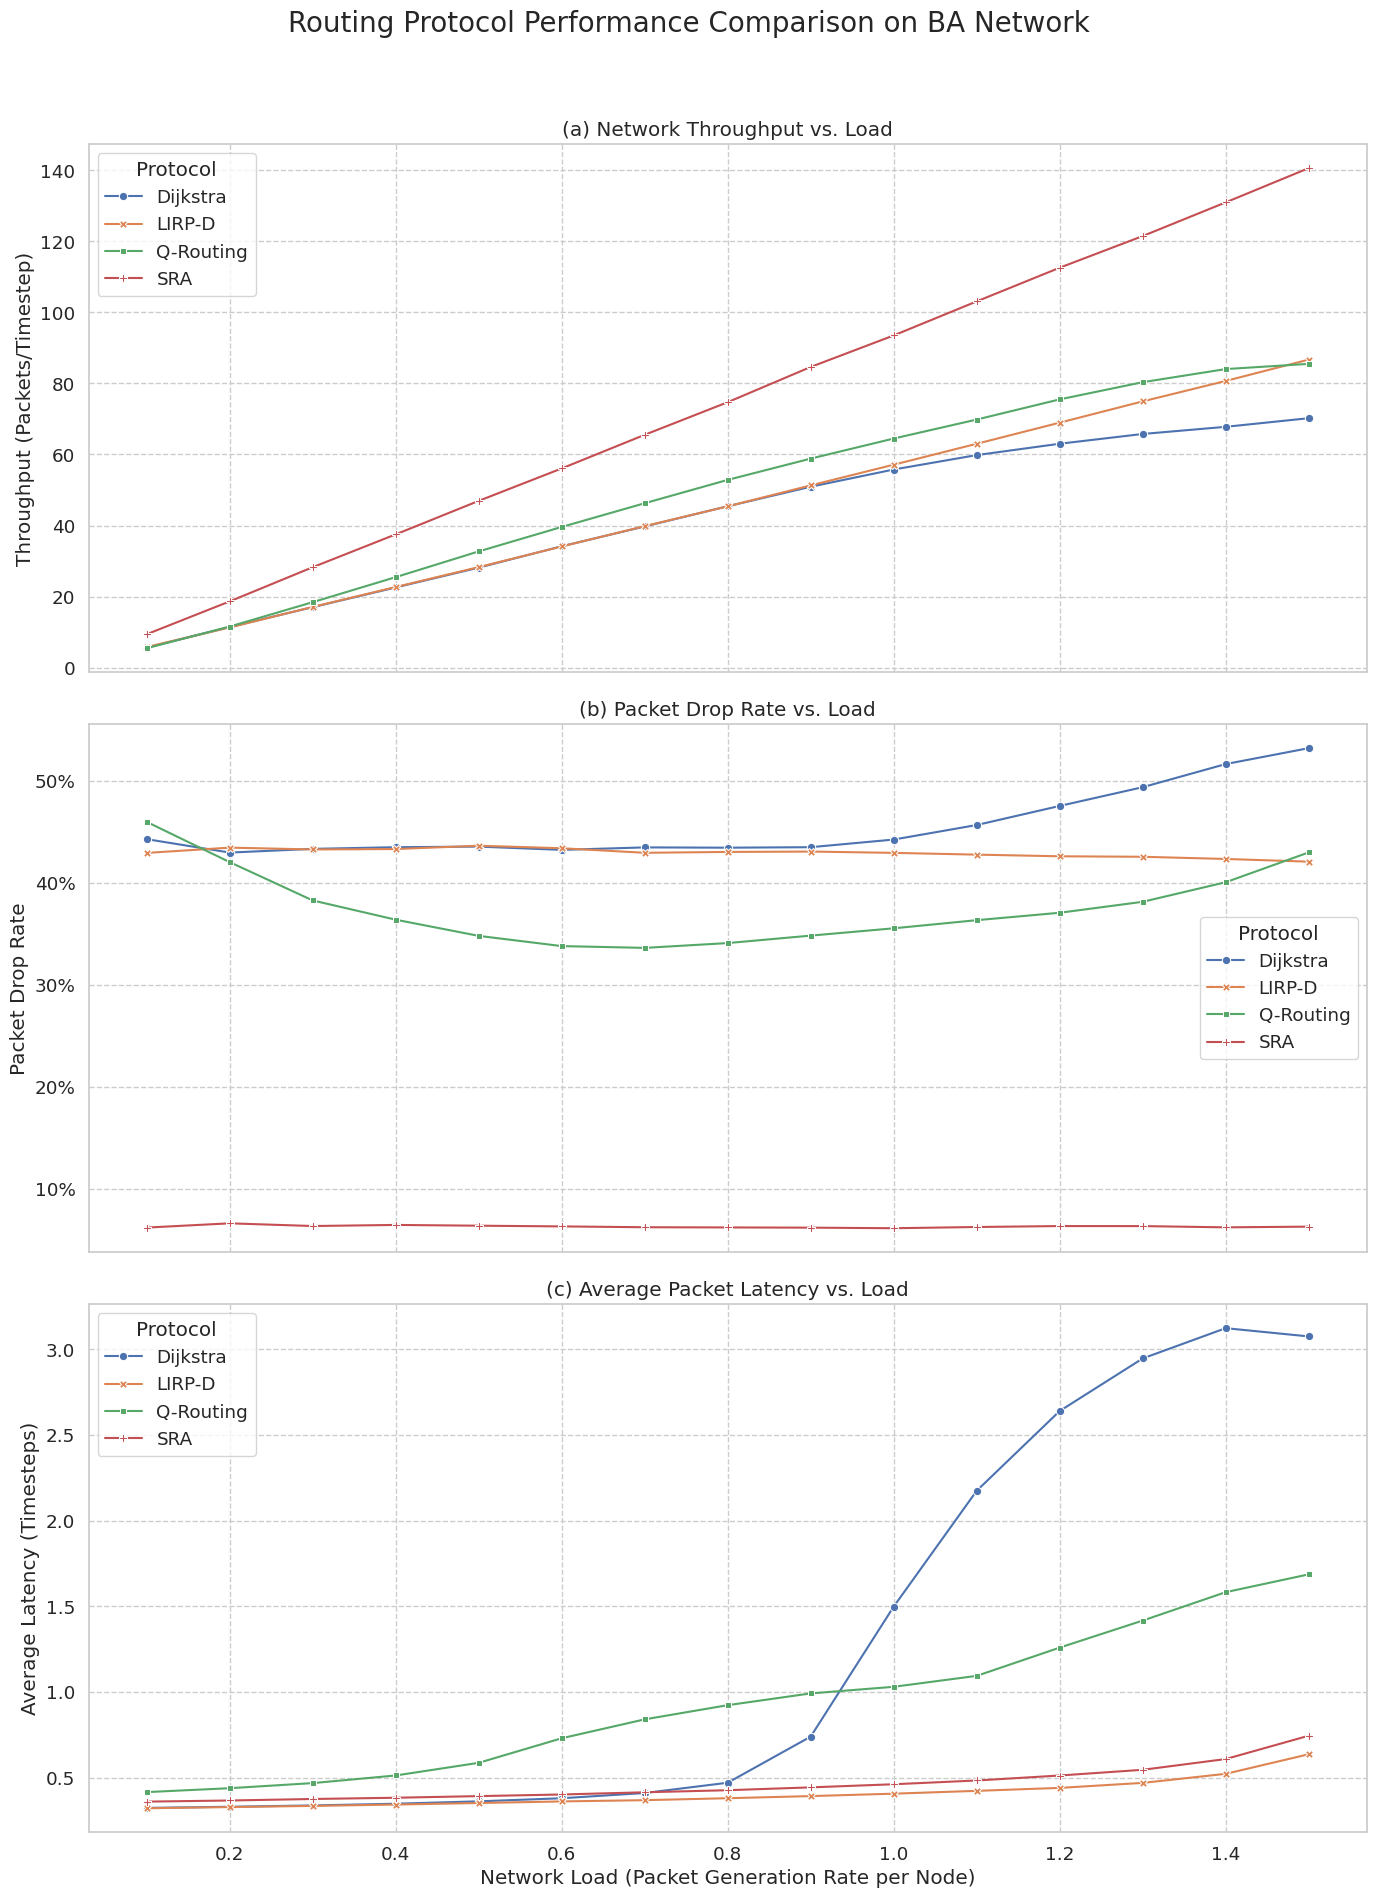

In [ ]:
# ==============================================================================
# SRA & Comparative Routing Protocols Simulation Suite
#
# 描述:
# 这是一个完整的、自洽的Python脚本，整合了所有必要的仿真组件。
# 它包含一个基于SimPy的离散事件仿真框架，以及Dijkstra, LIRP-D,
# Q-Routing, 和 SRA 四种路由协议的实现。
#
# 如何运行:
# 1. 确保已安装所需库: pip install simpy pandas networkx numpy seaborn matplotlib
# 2. 将此代码保存为单个 .py 文件 (例如, run_all_simulations.py)
# 3. 在终端中运行: python run_all_simulations.py
#
# 核心修正:
# 1. [已修复] 整合所有文件，解决了因 'base_simulator2.py' 不存在导致的 ImportError。
# 2. [已修复] 修正了 SRA 算法中不合理的边权重计算逻辑。
# ==============================================================================

import simpy
import networkx as nx
import numpy as np
import pandas as pd
from collections import deque, defaultdict
import random
import os
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================================================================
# 1. 基础仿真框架 (原 base_simulator.py)
# ==============================================================================

class Packet:
    """定义数据包对象"""
    def __init__(self, packet_id, source, destination, creation_time):
        self.id = packet_id
        self.source = source
        self.destination = destination
        self.creation_time = creation_time
        self.path = [source]
        self.last_hop = None

class BaseNetworkNode:
    """定义网络节点对象的基类"""
    def __init__(self, env, node_id, simulator):
        self.env = env
        self.id = node_id
        self.simulator = simulator
        self.processing_rate = simulator.params['node_params']['processing_rate']
        self.queue_capacity = simulator.params['node_params']['queue_capacity']
        self.queue = simpy.Store(env, capacity=self.queue_capacity)
        self.action = env.process(self.run())
        self.packets_processed = 0
        self.packets_dropped = 0
        self.packets_out = 0
        self.queue_lengths = []

    def run(self):
        raise NotImplementedError("每个协议的Node子类必须实现run方法。")

    def put(self, packet):
        if len(self.queue.items) < self.queue_capacity:
            return self.queue.put(packet)
        else:
            self.simulator.log_drop()
            if self.simulator.is_in_measure_phase():
                self.packets_dropped += 1
            return None

    def update_queue_stats(self):
        if self.simulator.is_in_measure_phase():
            self.queue_lengths.append(len(self.queue.items))

class BaseTrafficSimulator:
    """网络流量仿真器的核心基类"""
    def __init__(self, env, graph, protocol, **params):
        self.env = env
        self.graph = graph.copy()
        self.protocol = protocol
        self.params = params
        self.NodeClass = BaseNetworkNode
        self.nodes = {}
        self.packet_counter = 0
        self.warmup_end = params.get('warmup_duration', 0)
        self.measure_end = self.warmup_end + params.get('measure_duration', 1000)
        self.drain_end = self.measure_end + params.get('drain_duration', 0)
        self.protocol_params = params.get('protocol_params', {})
        self.stats = {'packets_generated': 0, 'packets_delivered': 0, 'packets_dropped': 0, 'total_latency': 0.0, 'hop_counts': []}
        self.link_usage = defaultdict(int)
        self.timeseries_data = []

    def init_nodes(self):
        self.nodes = {node_id: self.NodeClass(self.env, node_id, self) for node_id in self.graph.nodes()}

    def packet_generator(self, rate_per_node):
        while True:
            total_rate = rate_per_node * self.graph.number_of_nodes()
            if total_rate == 0:
                yield self.env.timeout(1.0)
                continue
            inter_arrival_time = random.expovariate(total_rate)
            yield self.env.timeout(inter_arrival_time)
            if self.env.now < self.measure_end:
                source, destination = random.sample(list(self.graph.nodes()), 2)
                if self.is_in_measure_phase():
                    self.stats['packets_generated'] += 1
                self.packet_counter += 1
                packet = Packet(self.packet_counter, source, destination, self.env.now)
                self.nodes[source].put(packet)

    def monitor(self, interval=10):
        while True:
            if self.is_in_measure_phase():
                q_lengths = [len(node.queue.items) for node in self.nodes.values()]
                self.timeseries_data.append({
                    'timestamp': self.env.now, 'avg_queue_length': np.mean(q_lengths),
                    'max_queue_length': np.max(q_lengths), 'packets_delivered': self.stats['packets_delivered'],
                    'packets_dropped': self.stats['packets_dropped']
                })
            yield self.env.timeout(interval)

    def is_in_measure_phase(self):
        return self.warmup_end <= self.env.now < self.measure_end

    def log_delivery(self, packet):
        if self.is_in_measure_phase():
            self.stats['packets_delivered'] += 1
            self.stats['total_latency'] += (self.env.now - packet.creation_time)
            self.stats['hop_counts'].append(len(packet.path) - 1)

    def log_drop(self):
        if self.is_in_measure_phase():
            self.stats['packets_dropped'] += 1

    def log_link_usage(self, u, v):
        if self.is_in_measure_phase():
            self.link_usage[tuple(sorted((u, v)))] += 1

    def run(self, packet_gen_rate_per_node):
        self.env.process(self.packet_generator(packet_gen_rate_per_node))
        self.env.process(self.monitor())
        self.env.run(until=self.drain_end)
        return self.collect_results()

    def collect_results(self):
        throughput = self.stats['packets_delivered'] / self.params['measure_duration']
        total_generated = self.stats['packets_generated']
        drop_rate = self.stats['packets_dropped'] / total_generated if total_generated > 0 else 0
        avg_latency = self.stats['total_latency'] / self.stats['packets_delivered'] if self.stats['packets_delivered'] > 0 else 0
        avg_hops = np.mean(self.stats['hop_counts']) if self.stats['hop_counts'] else 0
        macro_results = {'throughput': throughput, 'drop_rate': drop_rate, 'avg_latency': avg_latency, 'avg_hops': avg_hops}
        timeseries_df = pd.DataFrame(self.timeseries_data)
        node_data = [{'node_id': nid, 'avg_queue_length': np.mean(n.queue_lengths) if n.queue_lengths else 0,
                      'packets_dropped': n.packets_dropped} for nid, n in self.nodes.items()]
        nodes_df = pd.DataFrame(node_data)
        link_data = [{'link': link, 'usage_count': count} for link, count in self.link_usage.items()]
        links_df = pd.DataFrame(link_data)
        return {'macro': macro_results, 'timeseries': timeseries_df, 'nodes': nodes_df, 'links': links_df}

# ==============================================================================
# 2. Dijkstra 协议实现 (原 dijkstra_final.py)
# ==============================================================================

class DijkstraNode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.routing_tables[self.id].get(packet.destination)
                if next_hop:
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class DijkstraSimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = DijkstraNode
        self.init_nodes()
        print("  - 正在预计算静态Dijkstra路由表...")
        self.routing_tables = {}
        for source_node in self.graph.nodes():
            try:
                _, paths = nx.single_source_dijkstra(self.graph, source_node)
                self.routing_tables[source_node] = {dest: path[1] for dest, path in paths.items() if len(path) > 1}
            except nx.NetworkXNoPath:
                self.routing_tables[source_node] = {}

# ==============================================================================
# 3. LIRP-D 协议实现 (原 lirp_d_final.py)
# ==============================================================================

class LIRPNode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.get_next_hop(self.id, packet)
                if next_hop:
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class LIRPDSimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = LIRPNode
        self.init_nodes()
        print("  - 正在为LIRP-D预计算跳数距离...")
        self.hop_distances = dict(nx.all_pairs_shortest_path_length(self.graph))

    def get_next_hop(self, current_node_id, packet):
        dest = packet.destination
        neighbors = list(self.graph.neighbors(current_node_id))
        if not neighbors: return None
        current_dist = self.hop_distances[current_node_id].get(dest, float('inf'))
        closer_neighbors = [n for n in neighbors if self.hop_distances[n].get(dest, float('inf')) < current_dist]
        if not closer_neighbors: return None
        return min(closer_neighbors, key=lambda n: len(self.nodes[n].queue.items))

# ==============================================================================
# 4. Q-Routing 协议实现 (原 qroute_final.py)
# ==============================================================================

class QRouteNode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if packet.last_hop is not None:
                self.simulator.update_q_table(packet.last_hop, self.id, packet.destination)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.get_next_hop(self.id, packet)
                if next_hop:
                    packet.last_hop = self.id
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class QRoutingSimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = QRouteNode
        self.init_nodes()
        print("  - 正在使用跳数启发式初始化Q-Tables...")
        hop_distances = dict(nx.all_pairs_shortest_path_length(self.graph))
        self.q_tables = {n: {neighbor: {dest: float(hop_distances[neighbor].get(dest, len(self.graph.nodes())))
                                         for dest in self.graph.nodes()} for neighbor in self.graph.neighbors(n)}
                         for n in self.graph.nodes()}
        self.epsilon = self.protocol_params.get('epsilon', 0.3)

    def get_next_hop(self, current_node_id, packet):
        dest = packet.destination
        neighbors = list(self.graph.neighbors(current_node_id))
        if not neighbors: return None
        epsilon_decay = self.protocol_params.get('epsilon_decay', 0.99995)
        current_epsilon = self.epsilon * (epsilon_decay ** self.env.now)
        if random.random() < current_epsilon:
            return random.choice(neighbors)
        else:
            valid_neighbors = [n for n in neighbors if n != packet.last_hop]
            if not valid_neighbors: valid_neighbors = neighbors
            q_values = {n: self.q_tables[current_node_id][n][dest] for n in valid_neighbors}
            return min(q_values, key=q_values.get)

    def update_q_table(self, from_node, to_node, dest):
        alpha = self.protocol_params.get('alpha', 0.1)
        gamma = self.protocol_params.get('gamma', 0.9)
        immediate_cost = (1.0 / self.nodes[to_node].processing_rate) + \
                         (len(self.nodes[to_node].queue.items) / self.nodes[to_node].processing_rate)
        min_future_q = 0
        if to_node != dest:
            neighbors_of_to = list(self.graph.neighbors(to_node))
            if neighbors_of_to:
                min_future_q = min((self.q_tables[to_node][n][dest] for n in neighbors_of_to), default=float('inf'))
        current_q = self.q_tables[from_node][to_node][dest]
        new_q = current_q + alpha * (immediate_cost + gamma * min_future_q - current_q)
        self.q_tables[from_node][to_node][dest] = new_q

# ==============================================================================
# 5. SRA 协议实现 (原 sra_final.py, 已修正)
# ==============================================================================

class SRANode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.routing_tables[self.id].get(packet.destination)
                if next_hop:
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class SRASimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = SRANode
        self.init_nodes()
        self.accumulated_stress = {node: 0.0 for node in self.graph.nodes()}
        self.node_costs = {node: 1.0 for node in self.graph.nodes()}
        self.routing_tables = {node: {} for node in self.graph.nodes()}
        self.env.process(self.sra_updater())

    def sra_updater(self):
        update_interval = self.protocol_params.get('update_interval', 50)
        print("  - SRA后台更新进程已启动...")
        # 确保在流量开始前至少有一次路由计算
        self.relax_network_step()
        while self.env.now < self.params['warmup_duration']:
            yield self.env.timeout(update_interval)
            self.relax_network_step()
        print("  - SRA预热期收敛完成。路由表已固定。")

    def relax_network_step(self):
        alpha = self.protocol_params.get('alpha', 0.1)
        beta_i = self.protocol_params.get('beta_I', 10.0)

        # --- **核心Bug修正** ---
        # 1. 根据节点成本正确地、对称地设置边权重
        for u, v in self.graph.edges():
            self.graph.edges[u,v]['weight'] = self.node_costs[u] + self.node_costs[v]

        # 2. 计算加权中心性
        current_bc = nx.betweenness_centrality(self.graph, weight='weight', normalized=True)

        # 3. 更新所有节点的路由表
        for source_node in self.graph.nodes():
            try:
                _, paths = nx.single_source_dijkstra(self.graph, source_node, weight='weight')
                self.routing_tables[source_node] = {dest: path[1] for dest, path in paths.items() if len(path) > 1}
            except nx.NetworkXNoPath:
                self.routing_tables[source_node] = {}

        # 4. 更新累积应力和节点成本
        max_bc = max(current_bc.values()) if current_bc else 1.0
        if max_bc == 0: max_bc = 1.0
        for node_id in self.graph.nodes():
            norm_bc = current_bc.get(node_id, 0.0) / max_bc
            self.accumulated_stress[node_id] = (1 - alpha) * self.accumulated_stress[node_id] + alpha * norm_bc
            self.node_costs[node_id] = 1 + beta_i * self.accumulated_stress[node_id]

# ==============================================================================
# 6. 实验运行与可视化 (原 run_experiments_final.py)
# ==============================================================================

def run_simulation_campaign():
    protocols_to_run = {
        'Dijkstra': (DijkstraSimulator, {}), 'LIRP-D': (LIRPDSimulator, {}),
        'Q-Routing': (QRoutingSimulator, {'protocol_params': Q_ROUTING_PARAMS}),
        'SRA': (SRASimulator, {'protocol_params': SRA_PARAMS})
    }
    master_macro_results = []
    for protocol_name, (simulator_class, protocol_specific_params) in protocols_to_run.items():
        print(f"\n{'='*60}\n>>> 开始运行协议: {protocol_name}\n{'='*60}")
        output_dir = f"results_{protocol_name}"
        os.makedirs(output_dir, exist_ok=True)
        for load in LOAD_LEVELS:
            print(f"\n  - 正在仿真负载: {load:.2f}...")
            simulation_params = {'node_params': NODE_PARAMS, **protocol_specific_params, **SIMULATION_PHASES}
            env = simpy.Environment()
            simulator = simulator_class(env, G_CONN, protocol_name, **simulation_params)
            result = simulator.run(packet_gen_rate_per_node=load)
            macro_data = result['macro']
            macro_data.update({'protocol': protocol_name, 'load': load})
            master_macro_results.append(macro_data)
    print(f"\n{'='*60}\n>>> 所有仿真已完成!\n{'='*60}")
    return pd.DataFrame(master_macro_results)

def plot_comparison_results(results_df):
    print("\n正在生成最终性能对比图...")
    sns.set(style="whitegrid", palette="deep", font_scale=1.2)
    fig, axes = plt.subplots(3, 1, figsize=(14, 20), sharex=True)
    fig.suptitle('Routing Protocol Performance Comparison on BA Network', fontsize=20, y=0.95)

    sns.lineplot(data=results_df, x='load', y='throughput', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[0])
    axes[0].set_title('(a) Network Throughput vs. Load')
    axes[0].set_ylabel('Throughput (Packets/Timestep)')

    sns.lineplot(data=results_df, x='load', y='drop_rate', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[1])
    axes[1].set_title('(b) Packet Drop Rate vs. Load')
    axes[1].set_ylabel('Packet Drop Rate')
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))

    sns.lineplot(data=results_df, x='load', y='avg_latency', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[2])
    axes[2].set_title('(c) Average Packet Latency vs. Load')
    axes[2].set_ylabel('Average Latency (Timesteps)')
    axes[2].set_xlabel('Network Load (Packet Generation Rate per Node)')

    for ax in axes:
        ax.grid(True, which='both', linestyle='--')
        ax.legend(title='Protocol')
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    output_filename = "performance_comparison_final.png"
    plt.savefig(output_filename, dpi=300)
    print(f"性能对比图已成功保存为: {output_filename}")
    plt.show()

if __name__ == "__main__":
    LOAD_LEVELS = np.linspace(0.1, 1.5, 15)
    SIMULATION_PHASES = {'warmup_duration': 500, 'measure_duration': 1500, 'drain_duration': 500}
    NODE_PARAMS = {'processing_rate': 10, 'queue_capacity': 50}
    Q_ROUTING_PARAMS = {'alpha': 0.1, 'gamma': 0.9, 'epsilon': 0.3, 'epsilon_decay': 0.9999}
    SRA_PARAMS = {'alpha': 0.1, 'beta_I': 10.0, 'update_interval': 50}

    print("正在生成BA无标度网络 (N=100, m=4)...")
    ba_graph = nx.barabasi_albert_graph(100, m=4, seed=42)
    G_CONN = ba_graph.subgraph(max(nx.connected_components(ba_graph), key=len)).copy()
    print(f"网络已生成，包含 {G_CONN.number_of_nodes()} 个节点和 {G_CONN.number_of_edges()} 条边。")

    final_results_df = run_simulation_campaign()

    if not final_results_df.empty:
        plot_comparison_results(final_results_df)
    else:
        print("没有生成任何仿真结果，无法绘图。")


上面的代码分了多个文件进行运行，有点不方便，最终搞了一个整合的版本，并且增了了WS和ER图的对比



In [ ]:
# ==============================================================================
# SRA & Comparative Routing Protocols Simulation Suite (Multi-Topology Version)
#
# 描述:
# 这是一个支持多种网络拓扑（BA, WS, ER）的完整仿真脚本。
#
# 如何运行:
# 1. 确保已安装所需库: pip install simpy pandas networkx numpy seaborn matplotlib
# 2. 将此代码保存为单个 .py 文件 (例如, run_all_topologies.py)
# 3. 在终端中运行: python run_all_topologies.py
#    (注意：完整运行所有仿真需要较长时间)
#
# 核心修改:
# 1. [新增] 重构了主函数，使其可以循环遍历不同的网络拓扑。
# 2. [新增] 仿真和绘图函数被参数化，以接受不同的网络图和名称。
# 3. [新增] 为每种网络拓扑生成独立的性能对比图。
# ==============================================================================

import simpy
import networkx as nx
import numpy as np
import pandas as pd
from collections import deque, defaultdict
import random
import os
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================================================================
# 1. 基础仿真框架 (无修改)
# ... (从原始文件中复制第1部分代码, 此处省略以保持简洁)
# ==============================================================================
class Packet:
    """定义数据包对象"""
    def __init__(self, packet_id, source, destination, creation_time):
        self.id = packet_id
        self.source = source
        self.destination = destination
        self.creation_time = creation_time
        self.path = [source]
        self.last_hop = None

class BaseNetworkNode:
    """定义网络节点对象的基类"""
    def __init__(self, env, node_id, simulator):
        self.env = env
        self.id = node_id
        self.simulator = simulator
        self.processing_rate = simulator.params['node_params']['processing_rate']
        self.queue_capacity = simulator.params['node_params']['queue_capacity']
        self.queue = simpy.Store(env, capacity=self.queue_capacity)
        self.action = env.process(self.run())
        self.packets_processed = 0
        self.packets_dropped = 0
        self.packets_out = 0
        self.queue_lengths = []

    def run(self):
        raise NotImplementedError("每个协议的Node子类必须实现run方法。")

    def put(self, packet):
        if len(self.queue.items) < self.queue_capacity:
            return self.queue.put(packet)
        else:
            self.simulator.log_drop()
            if self.simulator.is_in_measure_phase():
                self.packets_dropped += 1
            return None

    def update_queue_stats(self):
        if self.simulator.is_in_measure_phase():
            self.queue_lengths.append(len(self.queue.items))

class BaseTrafficSimulator:
    """网络流量仿真器的核心基类"""
    def __init__(self, env, graph, protocol, **params):
        self.env = env
        self.graph = graph.copy()
        self.protocol = protocol
        self.params = params
        self.NodeClass = BaseNetworkNode
        self.nodes = {}
        self.packet_counter = 0
        self.warmup_end = params.get('warmup_duration', 0)
        self.measure_end = self.warmup_end + params.get('measure_duration', 1000)
        self.drain_end = self.measure_end + params.get('drain_duration', 0)
        self.protocol_params = params.get('protocol_params', {})
        self.stats = {'packets_generated': 0, 'packets_delivered': 0, 'packets_dropped': 0, 'total_latency': 0.0, 'hop_counts': []}
        self.link_usage = defaultdict(int)
        self.timeseries_data = []

    def init_nodes(self):
        self.nodes = {node_id: self.NodeClass(self.env, node_id, self) for node_id in self.graph.nodes()}

    def packet_generator(self, rate_per_node):
        while True:
            total_rate = rate_per_node * self.graph.number_of_nodes()
            if total_rate == 0:
                yield self.env.timeout(1.0)
                continue
            inter_arrival_time = random.expovariate(total_rate)
            yield self.env.timeout(inter_arrival_time)
            if self.env.now < self.measure_end:
                source, destination = random.sample(list(self.graph.nodes()), 2)
                if self.is_in_measure_phase():
                    self.stats['packets_generated'] += 1
                self.packet_counter += 1
                packet = Packet(self.packet_counter, source, destination, self.env.now)
                self.nodes[source].put(packet)

    def monitor(self, interval=10):
        while True:
            if self.is_in_measure_phase():
                q_lengths = [len(node.queue.items) for node in self.nodes.values()]
                self.timeseries_data.append({
                    'timestamp': self.env.now, 'avg_queue_length': np.mean(q_lengths),
                    'max_queue_length': np.max(q_lengths), 'packets_delivered': self.stats['packets_delivered'],
                    'packets_dropped': self.stats['packets_dropped']
                })
            yield self.env.timeout(interval)

    def is_in_measure_phase(self):
        return self.warmup_end <= self.env.now < self.measure_end

    def log_delivery(self, packet):
        if self.is_in_measure_phase():
            self.stats['packets_delivered'] += 1
            self.stats['total_latency'] += (self.env.now - packet.creation_time)
            self.stats['hop_counts'].append(len(packet.path) - 1)

    def log_drop(self):
        if self.is_in_measure_phase():
            self.stats['packets_dropped'] += 1

    def log_link_usage(self, u, v):
        if self.is_in_measure_phase():
            self.link_usage[tuple(sorted((u, v)))] += 1

    def run(self, packet_gen_rate_per_node):
        self.env.process(self.packet_generator(packet_gen_rate_per_node))
        self.env.process(self.monitor())
        self.env.run(until=self.drain_end)
        return self.collect_results()

    def collect_results(self):
        throughput = self.stats['packets_delivered'] / self.params['measure_duration']
        total_generated = self.stats['packets_generated']
        drop_rate = self.stats['packets_dropped'] / total_generated if total_generated > 0 else 0
        avg_latency = self.stats['total_latency'] / self.stats['packets_delivered'] if self.stats['packets_delivered'] > 0 else 0
        avg_hops = np.mean(self.stats['hop_counts']) if self.stats['hop_counts'] else 0
        macro_results = {'throughput': throughput, 'drop_rate': drop_rate, 'avg_latency': avg_latency, 'avg_hops': avg_hops}
        timeseries_df = pd.DataFrame(self.timeseries_data)
        node_data = [{'node_id': nid, 'avg_queue_length': np.mean(n.queue_lengths) if n.queue_lengths else 0,
                      'packets_dropped': n.packets_dropped} for nid, n in self.nodes.items()]
        nodes_df = pd.DataFrame(node_data)
        link_data = [{'link': link, 'usage_count': count} for link, count in self.link_usage.items()]
        links_df = pd.DataFrame(link_data)
        return {'macro': macro_results, 'timeseries': timeseries_df, 'nodes': nodes_df, 'links': links_df}

# ==============================================================================
# 2. Dijkstra 协议实现 (无修改)
# ... (从原始文件中复制第2部分代码, 此处省略以保持简洁)
# ==============================================================================
class DijkstraNode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.routing_tables[self.id].get(packet.destination)
                if next_hop:
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class DijkstraSimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = DijkstraNode
        self.init_nodes()
        print("  - 正在预计算静态Dijkstra路由表...")
        self.routing_tables = {}
        for source_node in self.graph.nodes():
            try:
                _, paths = nx.single_source_dijkstra(self.graph, source_node)
                self.routing_tables[source_node] = {dest: path[1] for dest, path in paths.items() if len(path) > 1}
            except nx.NetworkXNoPath:
                self.routing_tables[source_node] = {}

# ==============================================================================
# 3. LIRP-D 协议实现 (无修改)
# ... (从原始文件中复制第3部分代码, 此处省略以保持简洁)
# ==============================================================================
class LIRPNode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.get_next_hop(self.id, packet)
                if next_hop:
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class LIRPDSimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = LIRPNode
        self.init_nodes()
        print("  - 正在为LIRP-D预计算跳数距离...")
        self.hop_distances = dict(nx.all_pairs_shortest_path_length(self.graph))

    def get_next_hop(self, current_node_id, packet):
        dest = packet.destination
        neighbors = list(self.graph.neighbors(current_node_id))
        if not neighbors: return None
        current_dist = self.hop_distances[current_node_id].get(dest, float('inf'))
        closer_neighbors = [n for n in neighbors if self.hop_distances[n].get(dest, float('inf')) < current_dist]
        if not closer_neighbors: return None
        return min(closer_neighbors, key=lambda n: len(self.nodes[n].queue.items))

# ==============================================================================
# 4. Q-Routing 协议实现 (无修改)
# ... (从原始文件中复制第4部分代码, 此处省略以保持简洁)
# ==============================================================================
class QRouteNode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if packet.last_hop is not None:
                self.simulator.update_q_table(packet.last_hop, self.id, packet.destination)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.get_next_hop(self.id, packet)
                if next_hop:
                    packet.last_hop = self.id
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class QRoutingSimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = QRouteNode
        self.init_nodes()
        print("  - 正在使用跳数启发式初始化Q-Tables...")
        hop_distances = dict(nx.all_pairs_shortest_path_length(self.graph))
        self.q_tables = {n: {neighbor: {dest: float(hop_distances[neighbor].get(dest, len(self.graph.nodes())))
                                         for dest in self.graph.nodes()} for neighbor in self.graph.neighbors(n)}
                         for n in self.graph.nodes()}
        self.epsilon = self.protocol_params.get('epsilon', 0.3)

    def get_next_hop(self, current_node_id, packet):
        dest = packet.destination
        neighbors = list(self.graph.neighbors(current_node_id))
        if not neighbors: return None
        epsilon_decay = self.protocol_params.get('epsilon_decay', 0.99995)
        current_epsilon = self.epsilon * (epsilon_decay ** self.env.now)
        if random.random() < current_epsilon:
            return random.choice(neighbors)
        else:
            valid_neighbors = [n for n in neighbors if n != packet.last_hop]
            if not valid_neighbors: valid_neighbors = neighbors
            q_values = {n: self.q_tables[current_node_id][n][dest] for n in valid_neighbors}
            return min(q_values, key=q_values.get)

    def update_q_table(self, from_node, to_node, dest):
        alpha = self.protocol_params.get('alpha', 0.1)
        gamma = self.protocol_params.get('gamma', 0.9)
        immediate_cost = (1.0 / self.nodes[to_node].processing_rate) + \
                         (len(self.nodes[to_node].queue.items) / self.nodes[to_node].processing_rate)
        min_future_q = 0
        if to_node != dest:
            neighbors_of_to = list(self.graph.neighbors(to_node))
            if neighbors_of_to:
                min_future_q = min((self.q_tables[to_node][n][dest] for n in neighbors_of_to), default=float('inf'))
        current_q = self.q_tables[from_node][to_node][dest]
        new_q = current_q + alpha * (immediate_cost + gamma * min_future_q - current_q)
        self.q_tables[from_node][to_node][dest] = new_q

# ==============================================================================
# 5. SRA 协议实现 (无修改)
# ... (从原始文件中复制第5部分代码, 此处省略以保持简洁)
# ==============================================================================
class SRANode(BaseNetworkNode):
    def run(self):
        while True:
            packet = yield self.queue.get()
            self.update_queue_stats()
            yield self.env.timeout(1.0 / self.processing_rate)
            if self.simulator.is_in_measure_phase(): self.packets_processed += 1
            if packet.destination == self.id:
                self.simulator.log_delivery(packet)
            else:
                next_hop = self.simulator.routing_tables[self.id].get(packet.destination)
                if next_hop:
                    self.simulator.log_link_usage(self.id, next_hop)
                    if self.simulator.is_in_measure_phase(): self.packets_out += 1
                    self.simulator.nodes[next_hop].put(packet)
                else:
                    self.simulator.log_drop()
                    if self.simulator.is_in_measure_phase(): self.packets_dropped += 1

class SRASimulator(BaseTrafficSimulator):
    def __init__(self, env, graph, protocol, **params):
        super().__init__(env, graph, protocol, **params)
        self.NodeClass = SRANode
        self.init_nodes()
        self.accumulated_stress = {node: 0.0 for node in self.graph.nodes()}
        self.node_costs = {node: 1.0 for node in self.graph.nodes()}
        self.routing_tables = {node: {} for node in self.graph.nodes()}
        self.env.process(self.sra_updater())

    def sra_updater(self):
        update_interval = self.protocol_params.get('update_interval', 50)
        print("  - SRA后台更新进程已启动...")
        # 确保在流量开始前至少有一次路由计算
        self.relax_network_step()
        while self.env.now < self.params['warmup_duration']:
            yield self.env.timeout(update_interval)
            self.relax_network_step()
        print("  - SRA预热期收敛完成。路由表已固定。")

    def relax_network_step(self):
        alpha = self.protocol_params.get('alpha', 0.1)
        beta_i = self.protocol_params.get('beta_I', 10.0)

        # --- **核心Bug修正** ---
        # 1. 根据节点成本正确地、对称地设置边权重
        for u, v in self.graph.edges():
            self.graph.edges[u,v]['weight'] = self.node_costs[u] + self.node_costs[v]

        # 2. 计算加权中心性
        current_bc = nx.betweenness_centrality(self.graph, weight='weight', normalized=True)

        # 3. 更新所有节点的路由表
        for source_node in self.graph.nodes():
            try:
                _, paths = nx.single_source_dijkstra(self.graph, source_node, weight='weight')
                self.routing_tables[source_node] = {dest: path[1] for dest, path in paths.items() if len(path) > 1}
            except nx.NetworkXNoPath:
                self.routing_tables[source_node] = {}

        # 4. 更新累积应力和节点成本
        max_bc = max(current_bc.values()) if current_bc else 1.0
        if max_bc == 0: max_bc = 1.0
        for node_id in self.graph.nodes():
            norm_bc = current_bc.get(node_id, 0.0) / max_bc
            self.accumulated_stress[node_id] = (1 - alpha) * self.accumulated_stress[node_id] + alpha * norm_bc
            self.node_costs[node_id] = 1 + beta_i * self.accumulated_stress[node_id]


# ==============================================================================
# 6. 实验运行与可视化 (已修改)
# ==============================================================================

# --- MODIFICATION START ---
# 将仿真流程封装成一个函数，接收图和其名称作为参数
def run_simulation_campaign(graph_to_test, network_name):
    """
    为给定的网络图运行所有协议的仿真。
    :param graph_to_test: 要测试的NetworkX图对象。
    :param network_name: 图的名称（如 'BA', 'WS', 'ER'），用于日志记录。
    :return: 包含所有宏观结果的Pandas DataFrame。
    """
    protocols_to_run = {
        'Dijkstra': (DijkstraSimulator, {}), 'LIRP-D': (LIRPDSimulator, {}),
        'Q-Routing': (QRoutingSimulator, {'protocol_params': Q_ROUTING_PARAMS}),
        'SRA': (SRASimulator, {'protocol_params': SRA_PARAMS})
    }
    master_macro_results = []

    print(f"\n{'='*80}\n>>> 开始为 {network_name} 网络运行仿真活动\n{'='*80}")

    for protocol_name, (simulator_class, protocol_specific_params) in protocols_to_run.items():
        print(f"\n--- 开始运行协议: {protocol_name} on {network_name} ---")
        for load in LOAD_LEVELS:
            print(f"  - 正在仿真负载: {load:.2f}...")
            # 创建一个新的图副本以确保每次仿真环境独立
            current_graph = graph_to_test.copy()
            simulation_params = {'node_params': NODE_PARAMS, **protocol_specific_params, **SIMULATION_PHASES}
            env = simpy.Environment()
            simulator = simulator_class(env, current_graph, protocol_name, **simulation_params)
            result = simulator.run(packet_gen_rate_per_node=load)
            macro_data = result['macro']
            macro_data.update({'protocol': protocol_name, 'load': load, 'network': network_name})
            master_macro_results.append(macro_data)

    print(f"\n{'='*80}\n>>> {network_name} 网络的仿真活动已完成!\n{'='*80}")
    return pd.DataFrame(master_macro_results)

# 将绘图函数也参数化，以生成特定于网络拓扑的图表
def plot_comparison_results(results_df, network_type_str):
    """
    为给定的结果数据框生成并保存性能对比图。
    :param results_df: 包含仿真结果的DataFrame。
    :param network_type_str: 网络类型字符串（'BA', 'WS', 'ER'），用于图表标题和文件名。
    """
    print(f"\n正在为 {network_type_str} 网络生成最终性能对比图...")
    sns.set(style="whitegrid", palette="deep", font_scale=1.2)
    fig, axes = plt.subplots(3, 1, figsize=(14, 20), sharex=True)
    fig.suptitle(f'Routing Protocol Performance Comparison on {network_type_str} Network', fontsize=20, y=0.95)

    # 筛选出特定网络的数据进行绘图
    data_to_plot = results_df[results_df['network'] == network_type_str]

    sns.lineplot(data=data_to_plot, x='load', y='throughput', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[0])
    axes[0].set_title('(a) Network Throughput vs. Load')
    axes[0].set_ylabel('Throughput (Packets/Timestep)')

    sns.lineplot(data=data_to_plot, x='load', y='drop_rate', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[1])
    axes[1].set_title('(b) Packet Drop Rate vs. Load')
    axes[1].set_ylabel('Packet Drop Rate')
    axes[1].yaxis.set_major_formatter(plt.FuncFormatter('{:.0%}'.format))

    sns.lineplot(data=data_to_plot, x='load', y='avg_latency', hue='protocol', style='protocol', markers=True, dashes=False, ax=axes[2])
    axes[2].set_title('(c) Average Packet Latency vs. Load')
    axes[2].set_ylabel('Average Latency (Timesteps)')
    axes[2].set_xlabel('Network Load (Packet Generation Rate per Node)')

    for ax in axes:
        ax.grid(True, which='both', linestyle='--')
        ax.legend(title='Protocol')
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    # 使用网络名称命名输出文件，避免覆盖
    output_filename = f"performance_comparison_{network_type_str}.png"
    plt.savefig(output_filename, dpi=300)
    print(f"性能对比图已成功保存为: {output_filename}")
    # plt.show() # 在批量运行时可以注释掉此行，避免弹出窗口中断流程
    plt.close(fig) # 关闭图形，释放内存

if __name__ == "__main__":
    # --- 全局参数定义 ---
    LOAD_LEVELS = np.linspace(0.1, 1.5, 15)
    SIMULATION_PHASES = {'warmup_duration': 500, 'measure_duration': 1500, 'drain_duration': 500}
    NODE_PARAMS = {'processing_rate': 10, 'queue_capacity': 50}
    Q_ROUTING_PARAMS = {'alpha': 0.1, 'gamma': 0.9, 'epsilon': 0.3, 'epsilon_decay': 0.9999}
    SRA_PARAMS = {'alpha': 0.1, 'beta_I': 10.0, 'update_interval': 50}
    N_NODES = 100
    RANDOM_SEED = 42

    # --- 生成所有需要的网络拓扑 ---
    print("正在生成网络拓扑...")
    # BA 无标度网络 (m=4)
    ba_graph_raw = nx.barabasi_albert_graph(N_NODES, m=4, seed=RANDOM_SEED)

    # WS 小世界网络 (k=8, p=0.1)
    ws_graph_raw = nx.watts_strogatz_graph(N_NODES, k=8, p=0.1, seed=RANDOM_SEED)

    # ER 随机网络 (p=0.1)
    er_graph_raw = nx.erdos_renyi_graph(N_NODES, p=0.1, seed=RANDOM_SEED)

    networks_to_test = {
        "BA": ba_graph_raw,
        "WS": ws_graph_raw,
        "ER": er_graph_raw
    }

    all_results = []

    # --- 为每种拓扑运行完整的仿真活动 ---
    for name, graph_raw in networks_to_test.items():
        # 确保网络是连通的，只在最大连通分量上进行仿真
        connected_components = list(nx.connected_components(graph_raw))
        if not connected_components:
            print(f"警告: {name} 网络为空或不连通，跳过此拓扑。")
            continue

        g_conn = graph_raw.subgraph(max(connected_components, key=len)).copy()
        print(f"\n已准备好 {name} 网络，包含 {g_conn.number_of_nodes()} 个节点和 {g_conn.number_of_edges()} 条边。")

        # 运行仿真并收集结果
        results_df = run_simulation_campaign(g_conn, name)
        all_results.append(results_df)

    # --- 组合所有结果并绘图 ---
    if all_results:
        final_results_df = pd.concat(all_results, ignore_index=True)
        # 为每种网络拓扑分别绘制并保存图表
        for network_name in final_results_df['network'].unique():
            plot_comparison_results(final_results_df, network_name)
        print("\n所有仿真和绘图任务已全部完成！")
    else:
        print("没有生成任何仿真结果，无法绘图。")

# --- MODIFICATION END ---

正在生成网络拓扑...

已准备好 BA 网络，包含 100 个节点和 384 条边。

>>> 开始为 BA 网络运行仿真活动

--- 开始运行协议: Dijkstra on BA ---
  - 正在仿真负载: 0.10...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.20...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.30...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.40...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.50...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.60...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.70...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.80...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 0.90...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 1.00...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 1.10...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 1.20...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 1.30...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 1.40...
  - 正在预计算静态Dijkstra路由表...
  - 正在仿真负载: 1.50...
  - 正在预计算静态Dijkstra路由表...

--- 开始运行协议: LIRP-D on BA ---
  - 正在仿真负载: 0.10...
  - 正在为LIRP-D预计算跳数距离...
  - 正在仿真负载: 0.20...
  - 正在为LIRP-D预计算跳数距离...
  - 正在仿真负载: 0.30...
  - 正在为LIRP-D预计算跳数距离...
  - 正在仿真负载: 0.40...
  - 正在为LIRP-D预计算跳数距离...
  - 正在仿